# **Libraries**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

from scipy.fft import fft, fftfreq

import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.nn.functional as F

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


import random
import pickle, os

# **Initial Hyperparameters**

In [ ]:
sequence_lenght = 96
prediction_lenght = 96
train_percentage = 0.80
d_model = 32
top_k = 14
BATCH_SIZE_TRAIN = 16
BATCH_SIZE_VAL = 16

# **Import Data**




In [ ]:
#data url
url = "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2025.zip"

#converting data in pandas dataframe
df = pd.read_csv(url, compression='zip', encoding='ISO-8859-1')

df

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m²),PAR (µmol/m²/s),max. PAR (µmol/m²/s),Tlog (degC),CO2 (ppm)
0,01.01.2025 00:10:00,997.30,-1.56,271.80,-2.97,90.0,5.45,4.90,0.54,3.06,...,1.61,3.87,148.9,0.0,0.0,0.0,0.0,0.0,6.24,456.9
1,01.01.2025 00:20:00,997.05,-0.90,272.48,-2.66,87.8,5.72,5.02,0.70,3.14,...,1.71,3.05,145.6,0.0,0.0,0.0,0.0,0.0,6.32,451.7
2,01.01.2025 00:30:00,996.96,-0.51,272.88,-2.44,86.7,5.89,5.10,0.78,3.19,...,1.61,3.31,146.9,0.0,0.0,0.0,0.0,0.0,6.46,451.0
3,01.01.2025 00:40:00,996.77,-0.27,273.14,-2.26,86.3,5.99,5.17,0.82,3.23,...,1.86,2.93,137.0,0.0,0.0,0.0,0.0,0.0,6.63,450.4
4,01.01.2025 00:50:00,996.62,-0.09,273.33,-2.14,86.0,6.07,5.22,0.85,3.26,...,1.25,2.23,131.3,0.0,0.0,0.0,0.0,0.0,6.82,450.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52555,31.12.2025 23:20:00,988.33,3.06,277.14,0.78,84.9,7.61,6.46,1.15,4.08,...,3.63,6.66,245.3,0.0,0.0,0.0,0.0,0.0,10.55,436.7
52556,31.12.2025 23:30:00,988.21,3.02,277.11,0.74,84.9,7.59,6.45,1.15,4.07,...,3.71,7.80,240.5,0.0,0.0,0.0,0.0,0.0,10.56,436.7
52557,31.12.2025 23:40:00,988.08,2.95,277.05,0.67,84.9,7.55,6.41,1.14,4.05,...,3.66,7.01,246.7,0.0,0.0,0.0,0.0,0.0,10.55,436.7
52558,31.12.2025 23:50:00,988.01,2.91,277.02,0.63,84.9,7.53,6.40,1.14,4.04,...,3.33,5.33,242.4,0.0,0.0,0.0,0.0,0.0,10.52,436.7


## DataFrame Cleaning

Removing column title and column Date Time





In [ ]:
if 'Date Time' in df.columns:
    df_numeric = df.drop(columns=['Date Time'])

df_numeric

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m²),PAR (µmol/m²/s),max. PAR (µmol/m²/s),Tlog (degC),CO2 (ppm)
0,997.30,-1.56,271.80,-2.97,90.0,5.45,4.90,0.54,3.06,4.92,...,1.61,3.87,148.9,0.0,0.0,0.0,0.0,0.0,6.24,456.9
1,997.05,-0.90,272.48,-2.66,87.8,5.72,5.02,0.70,3.14,5.03,...,1.71,3.05,145.6,0.0,0.0,0.0,0.0,0.0,6.32,451.7
2,996.96,-0.51,272.88,-2.44,86.7,5.89,5.10,0.78,3.19,5.12,...,1.61,3.31,146.9,0.0,0.0,0.0,0.0,0.0,6.46,451.0
3,996.77,-0.27,273.14,-2.26,86.3,5.99,5.17,0.82,3.23,5.19,...,1.86,2.93,137.0,0.0,0.0,0.0,0.0,0.0,6.63,450.4
4,996.62,-0.09,273.33,-2.14,86.0,6.07,5.22,0.85,3.26,5.24,...,1.25,2.23,131.3,0.0,0.0,0.0,0.0,0.0,6.82,450.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52555,988.33,3.06,277.14,0.78,84.9,7.61,6.46,1.15,4.08,6.54,...,3.63,6.66,245.3,0.0,0.0,0.0,0.0,0.0,10.55,436.7
52556,988.21,3.02,277.11,0.74,84.9,7.59,6.45,1.15,4.07,6.52,...,3.71,7.80,240.5,0.0,0.0,0.0,0.0,0.0,10.56,436.7
52557,988.08,2.95,277.05,0.67,84.9,7.55,6.41,1.14,4.05,6.49,...,3.66,7.01,246.7,0.0,0.0,0.0,0.0,0.0,10.55,436.7
52558,988.01,2.91,277.02,0.63,84.9,7.53,6.40,1.14,4.04,6.47,...,3.33,5.33,242.4,0.0,0.0,0.0,0.0,0.0,10.52,436.7


## PCA hypothesis

We can consider to perform the forecasting on after performing PCA on data.


In [ ]:
#PCA on data

#scaling on data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_numeric)

#performing PCA
pca = PCA(n_components=10)

#transforming data
X_pca = pca.fit_transform(X_scaled)
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', '6','7','8','9','10'])

#information check
info_explained = pca.explained_variance_ratio_

for i, var in enumerate(info_explained):
    print(f"{i+1}-th component: {var*100:.2f}%")

print(f"\nTotal: {sum(info_explained)*100:.2f}%")

1-th component: 46.45%
2-th component: 18.10%
3-th component: 8.32%
4-th component: 6.46%
5-th component: 5.38%
6-th component: 4.54%
7-th component: 3.98%
8-th component: 2.90%
9-th component: 1.96%
10-th component: 0.69%

Total: 98.78%


## Dataset Creation

In [ ]:
#depending on what we want to do we have to choose between one of the following lines
#X = X_pca
X = df_numeric.to_numpy()


In [ ]:
def dataset_creation(url_list, seq_len=96,
                     train_percentage = 0.8,
                     slipping = 0):
  """
  ------------------------------------------------------------------------
  Receives the list of urls as input (give them ordered from past to present)
  and gives back a usable datase
  ------------------------------------------------------------------------
  Params
  -----------
  url_list                                                 the list of url
  ------------------------------------------------------------------------
  Return
  ----------
  dataset: ndarray                                         the dataset
  ------------------------------------------------------------------------
  """
  def download_and_clean_data(url):
    #converting data in pandas dataframe
    df = pd.read_csv(url, compression='zip', encoding='ISO-8859-1')

    if 'Date Time' in df.columns:
      df_numeric = df.drop(columns=['Date Time'])

    return df_numeric.to_numpy()

  data = []

  for i, url in enumerate(url_list):
    try:
      data.append(download_and_clean_data(url))
      print(f"Downloaded {i}-th file: {url}")
      print(f"Remaning {len(url_list)-i} files")
    except Exception as e:
      print("Failed to download: ", url)


  data = np.concatenate(data)

   #cut the ones that avoid integer div
  remainder = data.shape[0] % seq_len
  if remainder != 0:
    data = data[:-remainder]

  if slipping > 0:
    division_grid = np.linspace(0,1, num=slipping, endpoint=False)
    for i in division_grid:
      data_to_add = data[int(seq_len*i):]
      remainder = data_to_add.shape[0] % seq_len
      if remainder != 0:
        data_to_add = data_to_add[:-remainder]

      data = np.concatenate([data, data_to_add])

  #reshape (B, T, c)
  data = data.reshape((data.shape[0]//seq_len, seq_len, data.shape[1]))

  #shuffle data
  idx = np.arange(data.shape[0])
  np.random.shuffle(idx)
  data = data[idx, :, :]

  #split train and test dataset
  train_dataset = data[:int(train_percentage*data.shape[0])]
  test_dataset = data[int(train_percentage*data.shape[0]):]


  return train_dataset, test_dataset

In [ ]:
def collect_data(url_list):
  """
  ------------------------------------------------------------------------
  Receives the list of urls as input (give them ordered from past to present)
  and gives back a usable datase
  ------------------------------------------------------------------------
  Params
  -----------
  url_list                                                 the list of url
  ------------------------------------------------------------------------
  Return
  ----------
  dataset: ndarray                                         the dataset
  ------------------------------------------------------------------------
  """
  def download_and_clean_data(url):
    #converting data in pandas dataframe
    df = pd.read_csv(url, compression='zip', encoding='ISO-8859-1')

    if 'Date Time' in df.columns:
      df_numeric = df.drop(columns=['Date Time'])

    return df_numeric.to_numpy()

  data = []

  for i, url in enumerate(url_list):
    try:
      data.append(download_and_clean_data(url))
      print(f"Downloaded {i}-th file: {url}")
      print(f"Remaning {len(url_list)-i} files")
    except Exception as e:
      print("Failed to download: ", url)


  data = np.concatenate(data)

  return data


def handle_data(data, seq_len=96, slipping=0):
    #cut the ones that avoid integer div
  remainder = data.shape[0] % seq_len
  if remainder != 0:
    data = data[:-remainder]

  if slipping > 0:
    division_grid = np.linspace(0,1, num=slipping, endpoint=False)
    for i in division_grid:
      data_to_add = data[int(seq_len*i):]
      remainder = data_to_add.shape[0] % seq_len
      if remainder != 0:
        data_to_add = data_to_add[:-remainder]

      data = np.concatenate([data, data_to_add])

  #reshape (B, T, c)
  data = data.reshape((data.shape[0]//seq_len, seq_len, data.shape[1]))

  #shuffle data
  idx = np.arange(data.shape[0])
  np.random.shuffle(idx)
  data = data[idx, :, :]

  #split train and test dataset
  train_dataset = data[:int(train_percentage*data.shape[0])]
  test_dataset = data[int(train_percentage*data.shape[0]):]


  return train_dataset, test_dataset

### CsvDataset and ToTensor classes

In [ ]:
class CsvDataset(Dataset):
    def __init__(self, dataset, transform=None):
        self.transform = transform
        self.data = dataset

    def __len__(self):
        return self.data.shape[0]   # fix: number of example

    def __getitem__(self, idx):
        sample = self.data[idx]
        if self.transform:
            sample = self.transform(sample)
        return sample


In [ ]:
class ToTensor(object):

    def __call__(self, sample):
        return torch.tensor(sample).float()

## Training and Test Data Splitting


In [ ]:
#https://www.bgc-jena.mpg.de/wetter/weather_data.html we used WS Beutenberg
#we take it starting from 2008 because before there where not 21 channels but 20
#the download takes around 2 minutes
urls = ["https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2024.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2025.zip"]

x_training, x_test = dataset_creation(urls, sequence_lenght + prediction_lenght, train_percentage,
                                      slipping = 2)

print(x_training.shape)
print(x_test.shape)

Downloaded 0-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip
Remaning 34 files
Downloaded 1-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip
Remaning 33 files
Downloaded 2-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip
Remaning 32 files
Downloaded 3-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip
Remaning 31 files
Downloaded 4-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip
Remaning 30 files
Downloaded 5-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip
Remaning 29 files
Downloaded 6-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip
Remaning 28 files
Downloaded 7-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip
Remaning 27 files
Downloaded 8-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip
Remaning 26 files
Downloaded 9-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip
Remaning 25 files
Downloaded 10-th file: https://www.bgc-jena.mpg.de/wetter/mp

In [ ]:
composed_transform = transforms.Compose([ToTensor()])

train_dataset = CsvDataset(x_training[:,:,1:2], transform=composed_transform)
val_dataset = CsvDataset(x_test[:,:,1:2], transform=composed_transform)
print(train_dataset.data.shape)
print(len(val_dataset))

(15775, 192, 1)
3944


In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE_TRAIN,
                              shuffle=True, num_workers=0)
val_dataloader  = DataLoader(val_dataset,  batch_size=BATCH_SIZE_VAL,
                             shuffle=False, num_workers=0)

print("train_dataset.shape:", len(train_dataset))
print("val_dataset.shape:", len(val_dataset))
print("len(train_dataloader):", len(train_dataloader))
print("len(val_dataloader):", len(val_dataloader))

train_dataset.shape: 15775
val_dataset.shape: 3944
len(train_dataloader): 986
len(val_dataloader): 247


# **Network Architecture**

##FFT

Apply the Fast Fourier Transform (FFT) to identify the dominant frequency components with the highest amplitudes.

### Frequency Inspection

In [ ]:
def fft_top_k_freq(X, k=10):
    """
    Parameters:
    X : Tensor shaped (B, T, C)
    k : number of max frequencies to return
    Returns:
      max_freqs : Tensor (k,) dominant frequencies
      max_amps  : Tensor (B, k) amplitude for each element in the batch
    """
    T_period = 1.0
    B, T, C = X.shape
    device = X.device

    #build fft frequencies
    xf = torch.fft.fftfreq(T, d=T_period, device=device)[:T // 2]

    #fft along time dim (dim=1) so yf is shaped (B, T//2, C)
    yf = torch.fft.fft(X, dim=1)[:, :T // 2, :]

    #mean aplitude over the channels and batches
    amp = torch.abs(yf).mean(dim=(0, 2))
    #amplitude over channels
    amp_per_batch = torch.abs(yf).mean(dim=2)

    #excluding the first component
    amp[0] = -1
    amp_per_batch[:, 0] = -1

    #top-k indexes over all the batch
    mask = torch.argsort(amp)[-k:].flip(dims=[0])
    max_freqs = xf[mask]                                    # (k,)
    max_amps = amp_per_batch[:, mask]                       # (B, k)

    return max_freqs, max_amps


### Feature Implementation

In [ ]:
def feature_implementation(X, k=10):
    """
    Parameters:
    X : Tensor shaped (B, T, C)
    k : number of max frequencies to return
    Returns:
      data : dict[int -> Tensor shape (C, num_periods, period)]
      weights : Tensor (B, k)  weights (amplitudes softmax)
    """
    device = X.device
    B, T, C = X.shape

    max_freqs, max_amps = fft_top_k_freq(X, k)
    #softmax along k for each batch
    weights = torch.softmax(max_amps, dim=1)

    data = {}

    for feature in range(k):
        frequency = max_freqs[feature]
        period_j = int(torch.abs(torch.round(frequency * T)).item())
        period_j = max(period_j, 1)

        if T // period_j < 2:
            #if period j is not long enough (less than half the lenght of the
            #time series) we don't modify the serie but just order the elements
            data[feature] = X.permute(0, 2, 1).unsqueeze(-1)   # (B, C, T, 1)
        else:
            remainder = T % period_j
            if remainder == 0:
                X_pad = X
            else:
                padding = torch.zeros(B, period_j - remainder, C, device=device)
                X_pad = torch.cat([X, padding], dim=1)          # (B, T_pad, C)

            num_periods = X_pad.shape[1] // period_j
            # (B, T_pad, C) -> (B, num_periods, period_j, C) -> (B, C, num_periods, period_j)
            data[feature] = X_pad.reshape(B, num_periods, period_j, C).permute(0, 3, 1, 2)

    return data, weights

## Inception Block

Applies multiple parallel operations (e.g., 1×1, 3×3, and 5×5 convolutions) to the same input tensor and concatenates the resulting feature maps along the channel dimension

In [ ]:
class InceptionBlock(nn.Module):
    """
    Input:
        x (Tensor): Input feature tensor. Expected shape: (Batch, Channels, Height, Width).
    Args:
        f_in: Number of input channels.
        f_out: Number of output channels.
        kernel: List of convolution kernel sizes applied in parallel
    Output:
        Tensor: Feature tensor obtained by averaging the outputs of multiple
          parallel convolutional branches. Shape: (Batch, f_out, Height, Width).

        """
    def __init__(self, f_in, f_out, kernel=[1,3,5,7]):
        super().__init__()
        self.f_in = f_in
        self.f_out = f_out
        self.kernel = kernel
        #self.stride = stride

        block = []
        for i in range(len(self.kernel)):
            block.append(nn.Conv2d(self.f_in, self.f_out, kernel_size=self.kernel[i], stride=1, padding='same'))
        self.block = nn.ModuleList(block)

    def forward(self, x):
      res_list = []
      for i in range(len(self.kernel)):
        #x_pad=F.pad(x,self.padding_list[i])
        #Maybe add some check for the kernel?
        res_list.append(self.block[i](x))
      res = torch.stack(res_list, dim=-1).mean(-1)    #INTRESTING COULD BE USING NOT THE MEAN
      return res


## TimesBlock
Transforms a 1D time series into a set of 2D tensors based on dominant
frequencies (extracted via batch-averaged Real FFT). Feature extraction is
delegated to an external 2D Inception module, and the results are mapped
back to 1D using frequency amplitudes as weighting factors.

Internal Flow:
1. FFT: Compute the top-k dominant frequencies averaged over Batch and Channels (excluding f=0).
2. Softmax: Compute aggregation weights based on the amplitudes of these frequencies.
3. 2D Reshape: For each frequency -> padding -> reshape to (Batch, Channels, Period, Num_Periods).
4. Inception: Pass the 2D grid through the inception_block to capture intra/inter-period variations.
5. 1D Reshape: Flatten back to 1D and remove padding to recover original length T.
6. Aggregation: Weighted sum of 1D outputs + residual connection with the original input.


In [ ]:
class TimesBlock(nn.Module):
    def __init__(self, seq_len, d_model, top_k, kernel=[1,3,5,7]):
        """
        Input:
            x (Tensor): Input time series tensor. Expected shape: (Batch, Time, Channels).
        Args:
            seq_len: input sequence length (T).
            d_model: Number of features/channels (C).
            top_k: Number of main frequencies to retain.
        Output:
            Tensor: Processed tensor with residual connection applied. Shape: (Batch, Time, Channels).
        """
        super().__init__()
        self.seq_len = seq_len
        self.d_model = d_model
        self.top_k = top_k
        self.inception = InceptionBlock(d_model, d_model, kernel)



    def forward(self, x):
        # x: (B, T, C)
        B, T, C = x.shape
        x_feat, weights = feature_implementation(x, k=self.top_k)   # weights: (B, k)
        n_features = len(x_feat)

        res = torch.zeros_like(x)

        for i in range(n_features):
            x_curr = x_feat[i]                        # (B, C, num_periods, period)
            out_2d = self.inception(x_curr)            # (B, C, num_periods, period)

            out_1d = out_2d.reshape(B, C, -1)          # (B, C, num_periods*period)
            out_1d = out_1d[:, :, :T]                  # tronca il padding
            out_1d = out_1d.permute(0, 2, 1)           # (B, T, C)

            w_i = weights[:, i].view(B, 1, 1)          # (B, 1, 1) per broadcasting su (B, T, C)
            res = res + out_1d * w_i

        return res + x

## Network 1
The base version of TimesNet

In [ ]:
class TimesNet(nn.Module):
    def __init__(self, seq_len, pred_len, n_channels, d_model, top_k, kernels):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.d_model = d_model
        self.top_k = top_k

        self.embedding = nn.Linear(n_channels, d_model)
        self.predict_linear = nn.Linear(self.seq_len, self.pred_len)
        self.times_blocks = nn.ModuleList([
            TimesBlock(self.seq_len,
                       d_model,
                       top_k,
                       kernel=kernels[i]) for i in range(kernels.shape[0])])
        self.layer_norms = nn.ModuleList([
                          nn.LayerNorm(d_model) for _ in range(kernels.shape[0])
                          ])
        self.projection = nn.Linear(d_model, n_channels)
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, x):
        means = x.mean(dim=1, keepdim=True).detach()        # (B, 1, C)
        stdev = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + 1e-5).detach()  # (B, 1, C)
        x = (x - means) / stdev
        x = self.embedding(x)                         # (B, T, d_model)
        x = self.dropout(x)

        for i in range(len(self.times_blocks)):
          x = self.times_blocks[i](x)
          x = self.layer_norms[i](x)
          x = self.dropout(x)

        x = self.predict_linear(x.permute(0,2,1))      # (B, d_model, seq_len+pred_len)
        x = x.permute(0,2,1)                            # (B, seq_len+pred_len, d_model)
        x = self.projection(x)          # (B, seq_len+pred_len, C)
        T_out = self.pred_len
        x = x * stdev.repeat(1, T_out, 1) + means.repeat(1, T_out, 1)

        return x # (B, pred_len, C)


## Network 1bis

Same as before but here the timesblocks are after the prediction

In [ ]:
class TimesNet1bis(nn.Module):
    def __init__(self, seq_len, pred_len, n_channels, d_model, top_k, kernels):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.d_model = d_model
        self.top_k = top_k

        self.embedding = nn.Linear(n_channels, d_model)
        self.predict_linear = nn.Linear(self.seq_len, self.pred_len + self.seq_len)
        self.times_blocks = nn.ModuleList([
            TimesBlock(self.seq_len + self.pred_len,
                       d_model,
                       top_k,
                       kernel=kernels[i]) for i in range(kernels.shape[0])])
        self.layer_norms = nn.ModuleList([
                          nn.LayerNorm(d_model) for _ in range(kernels.shape[0])
                          ])
        self.projection = nn.Linear(d_model, n_channels)
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, x):
        means = x.mean(dim=1, keepdim=True).detach()        # (B, 1, C)
        stdev = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + 1e-5).detach()  # (B, 1, C)
        x = (x - means) / stdev
        x = self.embedding(x)                         # (B, T, d_model)
        x = self.dropout(x)

        x = self.predict_linear(x.permute(0,2,1))      # (B, d_model, seq_len+pred_len)
        x = x.permute(0,2,1)                            # (B, seq_len+pred_len, d_model)

        for i in range(len(self.times_blocks)):
          x = self.times_blocks[i](x)
          x = self.layer_norms[i](x)
          x = self.dropout(x)

        x = self.projection(x)          # (B, seq_len+pred_len, C)
        T_out = self.pred_len + self.seq_len
        x = x * stdev.repeat(1, T_out, 1) + means.repeat(1, T_out, 1)

        return x[:,-self.pred_len:,:] # (B, pred_len, C)

## Network 2
Here, we introduce a linear layer after two TimesBlocks

In [ ]:
class TimesNet2(nn.Module):
    def __init__(self, seq_len, pred_len, n_channels, d_model, top_k, dropout, activation):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.d_model = d_model
        self.top_k = top_k

        activation_layers = {
            "relu": nn.ReLU,
            "gelu": nn.GELU,
            "silu": nn.SiLU,
        }
        if activation not in activation_layers:
            raise ValueError(
                f"Unsupported activation '{activation}'. "
                f"Choose one of {list(activation_layers)}."
            )
        self.activation_name = activation
        self.activation = activation_layers[activation]()

        hidden_dim = int(d_model + abs(n_channels - d_model) / 2)

        self.linear = nn.Linear(self.seq_len, self.seq_len)
        self.embedding = nn.Sequential(
            nn.Linear(n_channels, hidden_dim),
            activation_layers[activation](),
            nn.Linear(hidden_dim, d_model),
        )
        self.predict_linear = nn.Linear(self.seq_len, self.pred_len)
        self.times_blocks = TimesBlock(
            self.seq_len,
            d_model,
            top_k,
            kernel=[1, 3, 5]
        )
        self.projection = nn.Sequential(
            nn.Linear(d_model, hidden_dim),
            activation_layers[activation](),
            nn.Linear(hidden_dim, n_channels),
        )
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, x):
        means = x.mean(dim=1, keepdim=True).detach()  # (B, 1, C)
        stdev = torch.sqrt(
            x.var(dim=1, keepdim=True, unbiased=False) + 1e-5
        ).detach()  # (B, 1, C)
        x = (x - means) / stdev

        x = self.embedding(x)  # (B, seq_len, d_model)
        x = self.dropout(x)

        for _ in range(3):
            x = self.times_blocks(x)
            x = self.times_blocks(x)
            x = self.linear(x.permute(0, 2, 1))
            x = self.activation(x)
            x = self.dropout(x)
            x = x.permute(0, 2, 1)

        x = self.projection(x)  # (B, seq_len, n_channels)
        x = self.predict_linear(x.permute(0, 2, 1))  # (B, n_channels, pred_len)
        x = x.permute(0, 2, 1)  # (B, pred_len, n_channels)

        x = x * stdev.repeat(1, self.pred_len, 1) + means.repeat(
            1, self.pred_len, 1
        )

        return x  # (B, pred_len, n_channels)

## Network 3

we first to process each channel separately through each own TimesBlock pipeline

In [ ]:
class TimesNet3(nn.Module):
    def __init__(self, seq_len, pred_len, n_channels, d_model, top_k, kernels, kernels2):  #kernels--> indipendent channels, kernels2-> dipendent chanell
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.n_channels = n_channels
        self.d_model = d_model
        self.top_k = top_k

        self.predict_linear = nn.Linear(self.seq_len, self.pred_len)
        self.dropout = nn.Dropout(p=0.1)
        self.embedding = nn.Linear(n_channels, d_model)
        self.projection = nn.Linear(d_model, n_channels)

        #Independent analysis
        self.times_blocks1 = nn.ModuleList([TimesBlock(self.seq_len, 1, top_k, kernel=kernels[i]) for i in range(kernels.shape[0])])
        self.layer_norms1 = nn.ModuleList([nn.LayerNorm(1) for _ in range(kernels.shape[0])])

        #Dependent analysis
        self.times_blocks = nn.ModuleList([TimesBlock(self.seq_len, d_model, top_k, kernel=kernels2[i]) for i in range(kernels2.shape[0])])
        self.layer_norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(kernels2.shape[0])])


    def forward(self, x):
        means = x.mean(dim=1, keepdim=True).detach()        # (B, 1, C)
        stdev = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + 1e-5).detach()  # (B, 1, C)
        x = (x - means) / stdev

        #Independent
        out = []
        for j in range(self.n_channels):
            y = x[:,:,j:j+1]
            for i in range(len(self.times_blocks)):
              y = self.times_blocks1[i](y)
              y = self.layer_norms1[i](y)
              y = self.dropout(y)

            out.append(y)
        x = torch.cat(out, dim=2)

        #Dependet
        x = self.embedding(x)     # (B, T, d_model)
        x = self.dropout(x)
        for i in range(len(self.times_blocks)):
          x = self.times_blocks[i](x)
          x = self.layer_norms[i](x)
          x = self.dropout(x)

        x = self.predict_linear(x.permute(0,2,1))      # (B, d_model, seq_len+pred_len)
        x = x.permute(0,2,1)
        x = self.projection(x)                    # (B, seq_len+pred_len, C)
        T_out = self.pred_len
        x = x * stdev.repeat(1, T_out, 1) + means.repeat(1, T_out, 1)

        return x # (B, pred_len, C)

## Network 4
Implementation of PatchTST, a transformer network

In [ ]:
class PatchEmbedding(nn.Module):
    """
    Splits a 1-channel time series into overlapping patches and linearly
    embeds each patch into a d_model-dimensional token.

    Input:  x (Tensor) shape (B, seq_len)         -- one channel already
    Output: (B, num_patches, d_model)
    """
    def __init__(self, seq_len, patch_len, stride, d_model):
        super().__init__()
        self.patch_len = patch_len
        self.stride = stride

        # how many patches fit in the sequence
        self.num_patches = (seq_len - patch_len) // stride + 1

        # one shared linear layer projects each raw patch -> d_model
        self.patch_embed = nn.Linear(patch_len, d_model)

        # learned positional encoding: one vector per patch position
        self.pos_embed = nn.Parameter(torch.randn(1, self.num_patches, d_model) * 0.02)

    def forward(self, x):
        # x: (B, seq_len) -> unfold into overlapping windows
        # unfold(dim, size, step): (B, num_patches, patch_len)
        x = x.unfold(dimension=1, size=self.patch_len, step=self.stride)
        x = self.patch_embed(x)          # (B, num_patches, d_model)
        x = x + self.pos_embed           # broadcast add positional info
        return x


class TransformerEncoderBlock(nn.Module):
    """
    One standard pre-norm Transformer encoder layer:
    self-attention + feedforward, both with residual connections.
    """
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # Pre-norm self-attention block
        normed = self.norm1(x)
        attn_out, _ = self.attn(normed, normed, normed, need_weights=False)
        x = x + self.dropout(attn_out)

        # Pre-norm feedforward block
        x = x + self.dropout(self.ff(self.norm2(x)))
        return x


class PatchTST(nn.Module):
    """
    PatchTST-style forecaster (Nie et al., 2023), simplified for this project.

    Mirrors TimesNet's interface: forward(x) where
        x: (B, seq_len, C) -> returns (B, pred_len, C)

    Each channel is processed independently by the SAME shared model
    (channel independence), then outputs are stacked back together.

    Args:
        seq_len (int): length of input window (T)
        pred_len (int): number of future steps to predict
        n_channels (int): number of variates (C)
        d_model (int): token embedding dimension
        n_heads (int): number of attention heads
        n_layers (int): number of stacked Transformer encoder blocks
        patch_len (int): length of each patch
        stride (int): step between patch starts (stride < patch_len => overlapping patches)
        d_ff (int): hidden dim of the feedforward block inside each encoder layer
        dropout (float): dropout probability
    """
    def __init__(self, seq_len, pred_len, n_channels, d_model, n_heads,
                 n_layers, patch_len=16, stride=8, d_ff=None, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.n_channels = n_channels

        if d_ff is None:
            d_ff = d_model * 4   # standard Transformer convention

        self.patch_embedding = PatchEmbedding(seq_len, patch_len, stride, d_model)
        num_patches = self.patch_embedding.num_patches

        self.encoder = nn.ModuleList([
            TransformerEncoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])

        # Flatten all patch tokens, then linearly project straight to pred_len.
        # This is a direct (non-autoregressive) one-shot forecast head.
        self.head = nn.Linear(num_patches * d_model, pred_len)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (B, T, C)
        B, T, C = x.shape

        # --- Instance normalization (same idea as TimesNet.forward) ---
        means = x.mean(dim=1, keepdim=True).detach()                              # (B, 1, C)
        stdev = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + 1e-5).detach()  # (B, 1, C)
        x = (x - means) / stdev

        # --- Process each channel independently through the SAME model ---
        channel_outputs = []
        for c in range(C):
            x_c = x[:, :, c]                       # (B, T)  -- one channel

            tokens = self.patch_embedding(x_c)      # (B, num_patches, d_model)
            tokens = self.dropout(tokens)

            for block in self.encoder:
                tokens = block(tokens)               # (B, num_patches, d_model)

            flat = tokens.reshape(B, -1)             # (B, num_patches * d_model)
            pred_c = self.head(flat)                 # (B, pred_len)
            channel_outputs.append(pred_c)

        out = torch.stack(channel_outputs, dim=-1)   # (B, pred_len, C)

        # --- De-normalize (undo the instance norm from above) ---
        out = out * stdev.repeat(1, self.pred_len, 1) + means.repeat(1, self.pred_len, 1)

        return out

# **First Training**

## Training Function


In [ ]:
# TRAINING FUNCTION

def train_epoch(timesnet, device, dataloader, loss_fn, optimizer):
    timesnet.train()
    losses = []
    # Iterate the dataloader
    for something in dataloader:
        something = something.to(device)
        x = something[:, :-prediction_lenght, :]
        y = something[:, -prediction_lenght:, :]

        time_data = timesnet(x)
        loss = loss_fn(time_data,y)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.detach().cpu().numpy())

    losses = np.mean(losses)
    print(f"AVERAGE TRAIN LOSS: {losses}")

    return losses



# VALIDATION FUNCTION

def val_epoch(timesnet, device, dataloader, loss_fn, optimizer):
    timesnet.eval()
    losses = []
    with torch.no_grad():
      for something in dataloader:
        something = something.to(device)
        x = something[:, :-prediction_lenght, :]
        y = something[:, -prediction_lenght:, :]

        time_data = timesnet(x)
        loss = loss_fn(time_data,y)

        losses.append(loss.detach().cpu().numpy())

    losses = np.mean(losses)
    print(f"AVERAGE VAL LOSS: {losses}")

    return losses


## Net Initialization

In [ ]:
torch.manual_seed(0)

#'''
timesnet = TimesNet(
    seq_len=sequence_lenght,
    pred_len = prediction_lenght,
    n_channels=1,
    d_model=1,
    top_k=10,
    kernels=np.array([[1,3], [1,3]])
    )

#'''

'''
timesnet = TimesNet2(
    seq_len=sequence_lenght,
    pred_len = prediction_lenght,
    n_channels=1,
    d_model=1,
    top_k=top_k,
    dropoout=0.1,
    activation="relu"
    )
#'''

'''
timesnet = TimesNet3(
    seq_len=sequence_lenght,
    pred_len = prediction_lenght,
    n_channels=1,
    d_model=d_model,
    top_k=top_k,
    kernels=np.array([[1,3], [1,3]]),
    kernels2=np.array([[1,3]])
    )
#'''

'''
patchtst = PatchTST(
    seq_len=sequence_lenght,
    pred_len=prediction_lenght,
    n_channels=1,
    d_model=32,
    n_heads=4,
    n_layers=2,
    patch_len=16,
    stride=8,
)
'''

sample = torch.Tensor([x_training[0,:,1:2]])   # (1, T, C)
x_input = sample[:, :-prediction_lenght, :]
print(sample.shape, x_input.shape)

out = timesnet(x_input)
print(out.shape)




torch.Size([1, 192, 1]) torch.Size([1, 96, 1])
torch.Size([1, 96, 1])


## Training


In [ ]:
# Define the loss function
loss_fn = torch.nn.MSELoss()


# Define an optimizer
lr =5e-4 # Learning rate
params_to_optimize = [
    {'params': timesnet.parameters()}
]
optim = torch.optim.Adam(params_to_optimize, lr=lr, weight_decay=1e-4)


# Check if the GPU is available
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Training device: {device}")

timesnet.to(device)

print()


Training device: cpu



In [ ]:
#TRAINING LOOP

num_epochs = 10
train_err = []
val_err = []
for i in range(num_epochs):
    print('#################')
    print(f'# EPOCH {i}')
    print('#################')
    te = train_epoch(timesnet, device, train_dataloader, loss_fn, optim)
    ve = val_epoch(timesnet, device, val_dataloader, loss_fn, optim)
    train_err.append(te)
    val_err.append(ve)


#################
# EPOCH 0
#################
AVERAGE TRAIN LOSS: 17.074495315551758
AVERAGE VAL LOSS: 16.151939392089844
#################
# EPOCH 1
#################
AVERAGE TRAIN LOSS: 16.412187576293945
AVERAGE VAL LOSS: 16.151836395263672
#################
# EPOCH 2
#################
AVERAGE TRAIN LOSS: 16.417808532714844
AVERAGE VAL LOSS: 16.143936157226562
#################
# EPOCH 3
#################
AVERAGE TRAIN LOSS: 16.41682243347168
AVERAGE VAL LOSS: 16.167388916015625
#################
# EPOCH 4
#################
AVERAGE TRAIN LOSS: 16.405202865600586
AVERAGE VAL LOSS: 16.156185150146484
#################
# EPOCH 5
#################
AVERAGE TRAIN LOSS: 16.40733528137207
AVERAGE VAL LOSS: 16.16541862487793
#################
# EPOCH 6
#################
AVERAGE TRAIN LOSS: 16.411346435546875
AVERAGE VAL LOSS: 16.1463565826416
#################
# EPOCH 7
#################
AVERAGE TRAIN LOSS: 16.405237197875977
AVERAGE VAL LOSS: 16.146081924438477
#################
# EPOCH 8
#

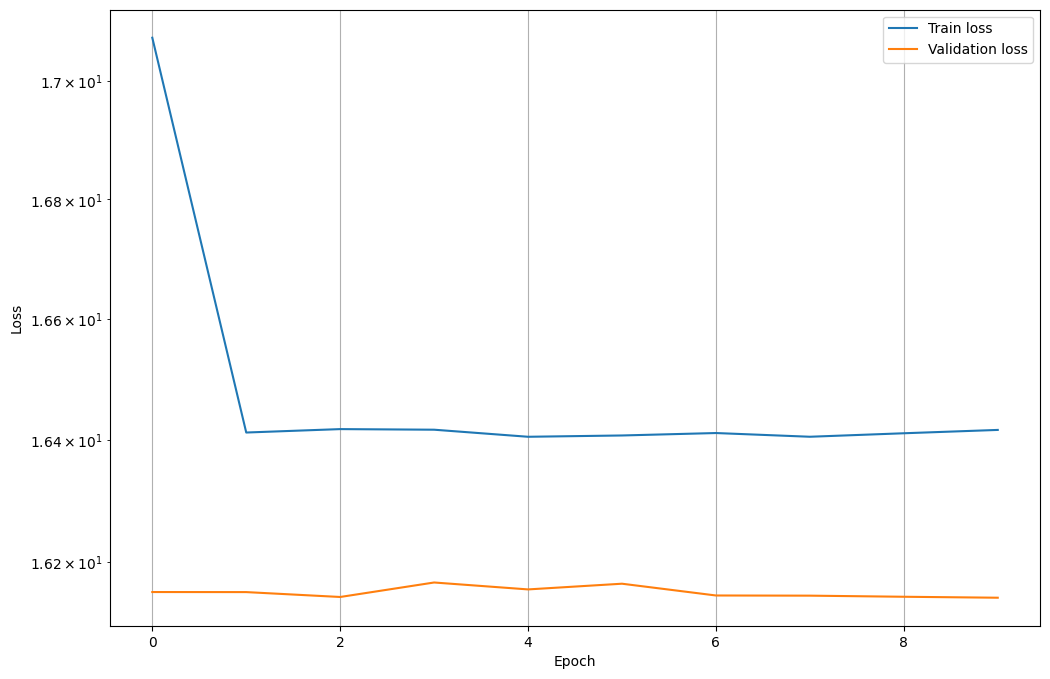

In [ ]:
# Plot losses
plt.figure(figsize=(12,8))
plt.semilogy(train_err, label='Train loss')
plt.semilogy(val_err, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()
plt.show()

torch.Size([3, 192, 1])
torch.Size([3, 96, 1])
torch.Size([3, 96, 1])


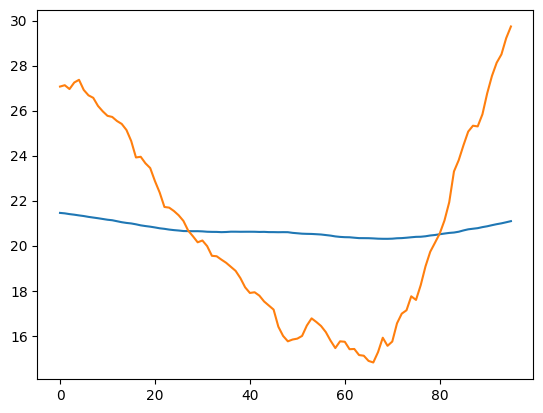

In [ ]:
#sample
sample = torch.Tensor(x_test[0:3,:,1:2])
sample = sample.to(device)
print(sample.shape)
y_pred = timesnet(sample[:,:-prediction_lenght, :])
y_true = sample[:, -prediction_lenght:, :]
print(y_pred.shape)
print(y_true.shape)

plt.plot(y_pred[2, :,0].cpu().detach().numpy())
plt.plot(y_true[2,:,0].cpu().detach().numpy())


# **Test and Analysis**

## Prediction Lenght vs Loss

In [ ]:
def run_loss_prediction_len(data, prediction_lenght_list, sequence_lenght,
                            num_epochs = 5, num_exp=5):
  import copy
  mean = []
  std = []

  # Define the loss function
  loss_fn = torch.nn.MSELoss()

  # Define an optimizer
  lr =5e-3 # Learning rate
  device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
  print(f"Training device: {device}")


  for prediction_lenght in prediction_lenght_list:
    print(f"---------------------------------------")
    print(f"Prediction lenght: {prediction_lenght}")
    ratio_initial_pred = prediction_lenght//prediction_lenght_list[0]
    train_dataset, test_dataset = handle_data(data,
                                              seq_len=sequence_lenght + prediction_lenght,
                                              slipping=ratio_initial_pred)
    composed_transform = transforms.Compose([ToTensor()])
    train_dataset = CsvDataset(train_dataset[:,:,1:2], transform=composed_transform)
    val_dataset = CsvDataset(test_dataset[:,:,1:2], transform=composed_transform)
    BATCH_SIZE_TRAIN = 32
    BATCH_SIZE_VAL = 32

    train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE_TRAIN,
                                  shuffle=True, num_workers=0)
    val_dataloader  = DataLoader(val_dataset,  batch_size=BATCH_SIZE_VAL,
                                 shuffle=False, num_workers=0)

    min_losses = []
    # TRAINING FUNCTION

    def train_epoch(timesnet, device, dataloader, loss_fn, optimizer):
        timesnet.train()
        losses = []
        # Iterate the dataloader
        for something in dataloader:  #<-- TO CHECK
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = timesnet(x)
            loss = loss_fn(time_data,y) #<-- MISSING

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            losses.append(loss.detach().cpu().numpy())

        losses = np.mean(losses)
        print(f"AVERAGE TRAIN LOSS: {losses}")

        return losses



    # VALIDATION FUNCTION

    def val_epoch(timesnet, device, dataloader, loss_fn, optimizer):
        timesnet.eval()
        losses = []
        with torch.no_grad():
          for something in dataloader:  #<-- TO CHECK
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = timesnet(x)
            loss = loss_fn(time_data,y) #<-- MISSING

            losses.append(loss.detach().cpu().numpy())

        losses = np.mean(losses)
        print(f"AVERAGE VAL LOSS: {losses}")

        return losses

    for i in range(num_exp):
      timesnet = TimesNet(
        seq_len=sequence_lenght,
        pred_len = prediction_lenght,
        n_channels=1,
        d_model=d_model,
        top_k=top_k,
        kernels=np.array([[1,3,5], [1,3,5]])
        )
      params_to_optimize = [
      {'params': timesnet.parameters()}
      ]
      optim = torch.optim.Adam(params_to_optimize, lr=lr, weight_decay=1e-4)

      timesnet.to(device)
      min_val_loss = 10e9
      for i in range(num_epochs):
          print(f'    EPOCH {i}')
          te = train_epoch(timesnet, device, train_dataloader, loss_fn, optim)
          ve = val_epoch(timesnet, device, val_dataloader, loss_fn, optim)
          if ve < min_val_loss:
            min_val_loss = ve
      min_losses.append(min_val_loss)

    min_losses = np.array(min_losses)

    mean.append(np.mean(min_losses))
    std.append(np.std(min_losses))

  return mean, std

In [ ]:
urls = ["https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2024.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2025.zip"]

pred_list = [96, 192, 384, 768]


mean, std = run_loss_prediction_len(collect_data(urls), pred_list, 96, 5, 5)

Downloaded 0-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip
Remaning 34 files
Downloaded 1-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip
Remaning 33 files
Downloaded 2-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip
Remaning 32 files
Downloaded 3-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip
Remaning 31 files
Downloaded 4-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip
Remaning 30 files
Downloaded 5-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip
Remaning 29 files
Downloaded 6-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip
Remaning 28 files
Downloaded 7-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip
Remaning 27 files
Downloaded 8-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip
Remaning 26 files
Downloaded 9-th file: https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip
Remaning 25 files
Downloaded 10-th file: https://www.bgc-jena.mpg.de/wetter/mp

In [ ]:
w = (mean, std)
with open('mean_seq_vs_loss.pickle', 'wb') as handle:
    pickle.dump(w, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Sequence lenght vs validation *loss*

In [ ]:
def run_loss_sequence_len(data, sequence_lenght_list, prediction_lenght,
                            num_epochs = 5, num_exp=5):
  mean = []
  std = []

  # Define the loss function
  loss_fn = torch.nn.MSELoss()

  # Define an optimizer
  lr =5e-3 # Learning rate
  device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
  print(f"Training device: {device}")


  for sequence_lenght in sequence_lenght_list:
    print(f"---------------------------------------")
    print(f"Prediction lenght: {sequence_lenght}")
    ratio_initial_pred = sequence_lenght//sequence_lenght_list[0]
    train_dataset, test_dataset = handle_data(data,
                                              seq_len=sequence_lenght + prediction_lenght,
                                              slipping=ratio_initial_pred)
    composed_transform = transforms.Compose([ToTensor()])
    train_dataset = CsvDataset(train_dataset[:,:,1:2], transform=composed_transform)
    val_dataset = CsvDataset(test_dataset[:,:,1:2], transform=composed_transform)
    BATCH_SIZE_TRAIN = 32
    BATCH_SIZE_VAL = 32

    train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE_TRAIN,
                                  shuffle=True, num_workers=0)
    val_dataloader  = DataLoader(val_dataset,  batch_size=BATCH_SIZE_VAL,
                                 shuffle=False, num_workers=0)

    min_losses = []
    # TRAINING FUNCTION

    def train_epoch(timesnet, device, dataloader, loss_fn, optimizer):
        timesnet.train()
        losses = []
        # Iterate the dataloader
        for something in dataloader:  #<-- TO CHECK
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = timesnet(x)
            loss = loss_fn(time_data,y) #<-- MISSING

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            losses.append(loss.detach().cpu().numpy())

        losses = np.mean(losses)
        print(f"AVERAGE TRAIN LOSS: {losses}")

        return losses



    # VALIDATION FUNCTION

    def val_epoch(timesnet, device, dataloader, loss_fn, optimizer):
        timesnet.eval()
        losses = []
        with torch.no_grad():
          for something in dataloader:  #<-- TO CHECK
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = timesnet(x)
            loss = loss_fn(time_data,y) #<-- MISSING

            losses.append(loss.detach().cpu().numpy())

        losses = np.mean(losses)
        print(f"AVERAGE VAL LOSS: {losses}")

        return losses

    for i in range(num_exp):
      timesnet = TimesNet(
        seq_len=sequence_lenght,
        pred_len = prediction_lenght,
        n_channels=1,
        d_model=d_model,
        top_k=top_k,
        kernels=np.array([[1,3,5], [1,3,5]])
        )
      params_to_optimize = [
      {'params': timesnet.parameters()}
      ]
      optim = torch.optim.Adam(params_to_optimize, lr=lr, weight_decay=1e-4)

      timesnet.to(device)
      min_val_loss = 10e9
      for i in range(num_epochs):
          print(f'    EPOCH {i}')
          te = train_epoch(timesnet, device, train_dataloader, loss_fn, optim)
          ve = val_epoch(timesnet, device, val_dataloader, loss_fn, optim)
          if ve < min_val_loss:
            min_val_loss = ve
      min_losses.append(min_val_loss)

    min_losses = np.array(min_losses)

    mean.append(np.mean(min_losses))
    std.append(np.std(min_losses))

  return mean, std

In [ ]:
urls = ["https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2024.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2025.zip"]

seq_list = [96, 192, 384, 768]


mean, std = run_loss_prediction_len(collect_data(urls), seq_list, 96, 5, 5)

In [ ]:
w = (mean, std)
with open('mean_seq_vs_loss.pickle', 'wb') as handle:
    pickle.dump(w, handle, protocol=pickle.HIGHEST_PROTOCOL)

## PCA vs Full Feature Dataset

In [ ]:
import copy

# Check if the GPU is available
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Training device: {device}")

urls = ["https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023a.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023b.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2024.zip",
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2025.zip"]


data = collect_data(urls)

sequence_lenght = 96
prediction_lenght = 96
train_percentage = 0.8

x_training, x_test = handle_data(
    data,
    seq_len=sequence_lenght + prediction_lenght,
    slipping=0
)

print("x_training.shape:", x_training.shape)  # (B, T, 21)
print("x_test.shape:", x_test.shape)


B_train, T, C = x_training.shape
B_test = x_test.shape[0]

x_training_flat = x_training.reshape(-1, C)
x_test_flat = x_test.reshape(-1, C)

scaler = StandardScaler()
x_training_scaled = scaler.fit_transform(x_training_flat)
x_test_scaled = scaler.transform(x_test_flat)

pca9 = PCA(n_components=9)
x_training_pca_flat = pca9.fit_transform(x_training_scaled)
x_test_pca_flat = pca9.transform(x_test_scaled)

info_explained9 = pca9.explained_variance_ratio_
for i, var in enumerate(info_explained9):
    print(f"{i+1}-th component: {var*100:.2f}%")
print(f"\nTotal variance explained (9 comp, fit su train): {sum(info_explained9)*100:.2f}%\n")

x_training_pca = x_training_pca_flat.reshape(B_train, T, 9)
x_test_pca = x_test_pca_flat.reshape(B_test, T, 9)

print("x_training_pca.shape:", x_training_pca.shape)
print("x_test_pca.shape:", x_test_pca.shape)

composed_transform = transforms.Compose([ToTensor()])

train_dataset_21ch = CsvDataset(x_training, transform=composed_transform)
val_dataset_21ch   = CsvDataset(x_test, transform=composed_transform)

train_dataset_9pca = CsvDataset(x_training_pca, transform=composed_transform)
val_dataset_9pca   = CsvDataset(x_test_pca, transform=composed_transform)

BATCH_SIZE_TRAIN = 32
BATCH_SIZE_VAL = 32


def val_loss_in_original_space(y_pred, y_true, pca_model=None, scaler_model=None):
    if pca_model is not None and scaler_model is not None:
        B, P, C = y_pred.shape

        y_pred_np = y_pred.detach().cpu().numpy().reshape(-1, C)
        y_true_np = y_true.detach().cpu().numpy().reshape(-1, C)

        y_pred_scaled_space = pca_model.inverse_transform(y_pred_np)
        y_true_scaled_space = pca_model.inverse_transform(y_true_np)

        y_pred_orig = scaler_model.inverse_transform(y_pred_scaled_space)
        y_true_orig = scaler_model.inverse_transform(y_true_scaled_space)

        y_pred_orig = torch.tensor(y_pred_orig, dtype=torch.float32).reshape(B, P, 21)
        y_true_orig = torch.tensor(y_true_orig, dtype=torch.float32).reshape(B, P, 21)

        return torch.nn.functional.mse_loss(y_pred_orig, y_true_orig).item()
    else:
        return torch.nn.functional.mse_loss(y_pred, y_true).item()


def train_epoch(model, device, dataloader, loss_fn, optimizer):
    model.train()
    losses = []
    for something in dataloader:
        something = something.to(device)
        x = something[:, :-prediction_lenght, :]
        y = something[:, -prediction_lenght:, :]

        time_data = model(x)
        loss = loss_fn(time_data, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.detach().cpu().numpy())

    losses = np.mean(losses)
    print(f"AVERAGE TRAIN LOSS: {losses}")
    return losses


def val_epoch(model, device, dataloader, loss_fn, optimizer,
              pca_model=None, scaler_model=None):
    model.eval()
    native_losses = []
    orig_space_losses = []

    with torch.no_grad():
        for something in dataloader:
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = model(x)

            native_loss = loss_fn(time_data, y)
            native_losses.append(native_loss.detach().cpu().numpy())

            orig_loss = val_loss_in_original_space(
                time_data, y, pca_model=pca_model, scaler_model=scaler_model
            )
            orig_space_losses.append(orig_loss)

    native_losses = np.mean(native_losses)
    orig_space_losses = np.mean(orig_space_losses)

    print(f"AVERAGE VAL LOSS (spazio nativo del modello): {native_losses}")
    print(f"AVERAGE VAL LOSS (spazio originale, 21 canali): {orig_space_losses}")

    return native_losses, orig_space_losses


def train_timesnet(n_channels, train_dl, val_dl, num_epochs=10, label="",
                    pca_model=None, scaler_model=None, seed=0):
    torch.manual_seed(seed)

    model = TimesNet(
        seq_len=sequence_lenght,
        pred_len=prediction_lenght,
        n_channels=n_channels,
        d_model=d_model,
        top_k=top_k,
        kernels=np.array([[1,3,5,7], [1,3,5,7], [1,3,5,7]])
    ).to(device)

    optim_local = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = torch.nn.MSELoss()

    train_err_local = []
    val_err_native_local = []
    val_err_orig_local = []
    best_ve_local = float('inf')
    best_state = None

    for i in range(num_epochs):
        print(f'################# [{label} | seed={seed}] EPOCH {i} #################')
        te = train_epoch(model, device, train_dl, loss_fn, optim_local)
        ve_native, ve_orig = val_epoch(
            model, device, val_dl, loss_fn, optim_local,
            pca_model=pca_model, scaler_model=scaler_model
        )
        train_err_local.append(te)
        val_err_native_local.append(ve_native)
        val_err_orig_local.append(ve_orig)

        if ve_orig < best_ve_local:
            print(f"--> [{label} | seed={seed}] Nuovo miglior score (spazio originale)! "
                  f"({ve_orig:.6f} < {best_ve_local:.6f}). Salvo il modello...")
            best_ve_local = ve_orig
            best_state = copy.deepcopy(model.state_dict())

    if best_state is not None:
        torch.save(best_state, f'best_timesnet_{label}_seed{seed}.pth')

    return model, train_err_local, val_err_native_local, val_err_orig_local


def make_seeded_dataloaders(seed):
    g = torch.Generator()
    g.manual_seed(seed)

    train_dl_21ch = DataLoader(train_dataset_21ch, batch_size=BATCH_SIZE_TRAIN,
                                shuffle=True, num_workers=0, generator=g)
    val_dl_21ch = DataLoader(val_dataset_21ch, batch_size=BATCH_SIZE_VAL,
                              shuffle=False, num_workers=0)

    g2 = torch.Generator()
    g2.manual_seed(seed)

    train_dl_9pca = DataLoader(train_dataset_9pca, batch_size=BATCH_SIZE_TRAIN,
                                shuffle=True, num_workers=0, generator=g2)
    val_dl_9pca = DataLoader(val_dataset_9pca, batch_size=BATCH_SIZE_VAL,
                              shuffle=False, num_workers=0)

    return train_dl_21ch, val_dl_21ch, train_dl_9pca, val_dl_9pca


n_experiments = 5
seeds = [0, 1, 2, 3, 4]

all_results = []

for exp_idx, seed in enumerate(seeds):
    print(f"\n{'='*60}")
    print(f"ESPERIMENTO {exp_idx + 1}/{n_experiments} — seed={seed}")
    print(f"{'='*60}\n")

    train_dl_21ch, val_dl_21ch, train_dl_9pca, val_dl_9pca = make_seeded_dataloaders(seed)

    model_21ch, train_err_21, val_err_21_native, val_err_21_orig = train_timesnet(
        n_channels=21,
        train_dl=train_dl_21ch,
        val_dl=val_dl_21ch,
        num_epochs=10,
        label="21ch_raw",
        pca_model=None,
        scaler_model=None,
        seed=seed
    )

    model_9pca, train_err_9pca, val_err_9pca_native, val_err_9pca_orig = train_timesnet(
        n_channels=9,
        train_dl=train_dl_9pca,
        val_dl=val_dl_9pca,
        num_epochs=10,
        label="9ch_pca",
        pca_model=pca9,
        scaler_model=scaler,
        seed=seed
    )

    all_results.append({
        'seed': seed,
        'best_val_21ch_orig': min(val_err_21_orig),
        'best_val_9pca_orig': min(val_err_9pca_orig),
        'train_err_21': train_err_21,
        'val_err_21_native': val_err_21_native,
        'val_err_21_orig': val_err_21_orig,
        'train_err_9pca': train_err_9pca,
        'val_err_9pca_native': val_err_9pca_native,
        'val_err_9pca_orig': val_err_9pca_orig,
    })


summary_df = pd.DataFrame([
    {
        'seed': r['seed'],
        'best_val_21ch_orig': r['best_val_21ch_orig'],
        'best_val_9pca_orig': r['best_val_9pca_orig'],
    }
    for r in all_results
])

print("\n=== RISULTATI PER ESPERIMENTO ===")
print(summary_df)

print("\n=== STATISTICHE AGGREGATE (su 5 esperimenti) ===")
print(f"21 canali (raw)  - Best Val Loss: media={summary_df['best_val_21ch_orig'].mean():.6f}, "
      f"std={summary_df['best_val_21ch_orig'].std():.6f}")
print(f"9 canali (PCA)   - Best Val Loss: media={summary_df['best_val_9pca_orig'].mean():.6f}, "
      f"std={summary_df['best_val_9pca_orig'].std():.6f}")


summary_df.to_csv('comparison_5_experiments.csv', index=False)

## Mean loss vs time step

In [ ]:
x, _ = dataset_creation(["https://www.bgc-jena.mpg.de/wetter/mpi_roof.zip"],
                        seq_len=192,
                        train_percentage=1,
                        slipping=0)

class TimesNet(nn.Module):
    def __init__(self, seq_len, pred_len, n_channels, d_model, top_k, kernels):
        super().__init__()
        self.seq_len = seq_len
        self.pred_len = pred_len
        self.d_model = d_model
        self.top_k = top_k

        self.embedding = nn.Linear(n_channels, d_model)
        self.predict_linear = nn.Linear(self.seq_len, self.pred_len)
        self.times_blocks = nn.ModuleList([
            TimesBlock(self.seq_len,
                       d_model,
                       top_k,
                       kernel=kernels[i]) for i in range(kernels.shape[0])])
        self.layer_norms = nn.ModuleList([
                          nn.LayerNorm(d_model) for _ in range(kernels.shape[0])
                          ])
        self.projection = nn.Linear(d_model, n_channels)
        self.dropout = nn.Dropout(p=0.1)

    def forward(self, x):
        means = x.mean(dim=1, keepdim=True).detach()        # (B, 1, C)
        stdev = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + 1e-5).detach()  # (B, 1, C)
        x = (x - means) / stdev
        x = self.embedding(x)                         # (B, T, d_model)
        x = self.dropout(x)

        for i in range(len(self.times_blocks)):
          x = self.times_blocks[i](x)
          x = self.layer_norms[i](x)
          x = self.dropout(x)

        x = self.predict_linear(x.permute(0,2,1))      # (B, d_model, seq_len+pred_len)
        x = x.permute(0,2,1)                            # (B, seq_len+pred_len, d_model)
        x = self.projection(x)          # (B, seq_len+pred_len, C)
        T_out = self.pred_len
        x = x * stdev.repeat(1, T_out, 1) + means.repeat(1, T_out, 1)

        return x # (B, pred_len, C)

#1 channel
timesnet = TimesNet(
    seq_len=96,
    pred_len = 96,
    n_channels=1,
    d_model=8,
    top_k=14,
    kernels=np.array([[1,3,5,7], [1,3,5,7], [1,3,5,7]])
    )

timesnet.load_state_dict(torch.load('best_timesnet_model (1).pth', map_location='cpu'))

timesnet.eval()

x = x[:,:,1:2]

print(x.shape)

import torch

x_tensor = torch.tensor(x, dtype=torch.float32)
pred = timesnet(x_tensor[:, :96,:])

true = x_tensor[:,96:,]
diff = (true - pred)
test_loss = (true - pred)**2
mean = diff.mean(dim=0).detach().numpy()[:,0]
std = diff.std(dim=0).detach().numpy()[:,0]
test_loss = test_loss.mean().detach().numpy()
print("Test loss", test_loss)


#pca 9 components
import joblib
import numpy as np
import torch

scaler = joblib.load('scaler_model.joblib')
pca = joblib.load('pca_model.joblib')

n_components = 9

timesnet_pca = TimesNet(
    seq_len=96,
    pred_len=96,
    n_channels=9,
    d_model=128,
    top_k=7,
    kernels=np.array([[1,3,5,7, 9], [1,3,5,7,9]])
)

timesnet_pca.load_state_dict(torch.load('/content/best_timesnet_9ch_pca_seed42.pth', map_location='cpu'))
timesnet_pca.eval()

print(x.shape)
N, T_tot, C = x.shape

x_flat = x.reshape(-1, C)          # (N*T_tot, C)
x_scaled = scaler.transform(x_flat)
x_pca = pca.transform(x_scaled)     # (N*T_tot, n_components)

x_pca = x_pca.reshape(N, T_tot, n_components)  #  (N, T_tot, n_components)
print(x_pca.shape)
x_pca_tensor = torch.tensor(x_pca, dtype=torch.float32)

pred_pca = timesnet_pca(x_pca_tensor[:, :96, :])   # (N, pred_len, n_components)
true_pca = x_pca_tensor[:, 96:, :]                  # (N, pred_len, n_components)

diff_pca = true_pca - pred_pca

mean_pca = diff_pca.mean(dim=0).detach().numpy()   # (pred_len, n_components)
std_pca = diff_pca.std(dim=0).detach().numpy()     # (pred_len, n_components)

def inverse_pca_scale(x_pca_tensor, pca, scaler):
    """
    x_pca_tensor: (N, T, n_components) tensor
    Ritorna: (N, T, C_original) numpy array
    """
    N, T, n_comp = x_pca_tensor.shape
    x_flat = x_pca_tensor.detach().numpy().reshape(-1, n_comp)
    x_unpca = pca.inverse_transform(x_flat)          # (N*T, C_original)
    x_unscaled = scaler.inverse_transform(x_unpca)    # (N*T, C_original)
    return x_unscaled.reshape(N, T, -1)

pred_orig = inverse_pca_scale(pred_pca, pca, scaler)   # (N, pred_len, C_original)
true_orig = inverse_pca_scale(true_pca, pca, scaler)   # (N, pred_len, C_original)

diff_orig = true_orig - pred_orig
test_loss = (true_orig - pred_orig)**2


mean_orig = diff_orig.mean(axis=0)   # (pred_len, C_original)
std_orig = diff_orig.std(axis=0)     # (pred_len, C_original)
test_loss = test_loss.mean().detach().numpy()
print("Test loss", test_loss)


## MSE vs First Step Bounded MSE

In [ ]:
def main():
    # Check if the GPU is available
    device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
    print(f"Training device: {device}")

    urls = ["https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2008b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2009b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2010b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2011b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2012b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2013b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2014b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2015b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2016b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2017b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2018b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2019b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2020b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2021b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2022b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023a.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2023b.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2024.zip",
            "https://www.bgc-jena.mpg.de/wetter/mpi_roof_2025.zip"]

    data = collect_data(urls)

    sequence_lenght = 96
    prediction_lenght = 97

    #harness of the bound
    OVERLAP_LOSS_WEIGHT = 100.0

    x_training, x_test = handle_data(
        data,
        seq_len=sequence_lenght + prediction_lenght - 1,  # 192
        slipping=4
    )

    print("x_training.shape:", x_training.shape)  # (B, T, 21)
    print("x_test.shape:", x_test.shape)

    B_train, T, C = x_training.shape
    B_test = x_test.shape[0]

    x_training_flat = x_training.reshape(-1, C)
    x_test_flat = x_test.reshape(-1, C)

    scaler = StandardScaler()
    x_training_scaled = scaler.fit_transform(x_training_flat)
    x_test_scaled = scaler.transform(x_test_flat)

    pca9 = PCA(n_components=9)
    x_training_pca_flat = pca9.fit_transform(x_training_scaled)
    x_test_pca_flat = pca9.transform(x_test_scaled)

    info_explained9 = pca9.explained_variance_ratio_
    for i, var in enumerate(info_explained9):
        print(f"{i+1}-th component: {var*100:.2f}%")
    print(f"\nTotal variance explained (9 comp, fit su train): {sum(info_explained9)*100:.2f}%\n")

    x_training_pca = x_training_pca_flat.reshape(B_train, T, 9)
    x_test_pca = x_test_pca_flat.reshape(B_test, T, 9)

    print("x_training_pca.shape:", x_training_pca.shape)
    print("x_test_pca.shape:", x_test_pca.shape)

    composed_transform = transforms.Compose([ToTensor()])

    train_dataset_9pca = CsvDataset(x_training_pca, transform=composed_transform)
    val_dataset_9pca = CsvDataset(x_test_pca, transform=composed_transform)

    BATCH_SIZE_TRAIN = 16
    BATCH_SIZE_VAL = 16

    def val_loss_in_original_space(y_pred, y_true, pca_model=None, scaler_model=None):
        if pca_model is not None and scaler_model is not None:
            B, P, Cc = y_pred.shape

            y_pred_np = y_pred.detach().cpu().numpy().reshape(-1, Cc)
            y_true_np = y_true.detach().cpu().numpy().reshape(-1, Cc)

            y_pred_scaled_space = pca_model.inverse_transform(y_pred_np)
            y_true_scaled_space = pca_model.inverse_transform(y_true_np)

            y_pred_orig = scaler_model.inverse_transform(y_pred_scaled_space)
            y_true_orig = scaler_model.inverse_transform(y_true_scaled_space)

            y_pred_orig = torch.tensor(y_pred_orig, dtype=torch.float32).reshape(B, P, 21)
            y_true_orig = torch.tensor(y_true_orig, dtype=torch.float32).reshape(B, P, 21)

            return torch.nn.functional.mse_loss(y_pred_orig, y_true_orig).item()
        else:
            return torch.nn.functional.mse_loss(y_pred, y_true).item()

    def overlap_step_error_orig_space(y_pred, y_true, pca_model=None, scaler_model=None):
        return val_loss_in_original_space(
            y_pred[:, :1, :], y_true[:, :1, :], pca_model, scaler_model
        )

    def make_weighted_mse_loss(overlap_weight, pred_len):

        weights = torch.ones(pred_len)
        weights[0] = overlap_weight
        weights = weights * (pred_len / weights.sum())
        weights = weights.view(1, pred_len, 1)

        def loss_fn(y_pred, y_true):
            w = weights.to(device=y_pred.device, dtype=y_pred.dtype)
            return ((y_pred - y_true) ** 2 * w).mean()

        return loss_fn

    def train_epoch(model, device, dataloader, loss_fn, optimizer,
                     pca_model=None, scaler_model=None):
        model.train()
        losses = []
        orig_losses = []
        orig_losses_fair = []
        overlap_losses = []
        for something in dataloader:
            something = something.to(device=device, dtype=torch.float32)

           x = something[:, :sequence_lenght, :]       # first 96 step (0..95)
            y = something[:, sequence_lenght - 1:, :]    # lasts 97 step (95..191)

            time_data = model(x)
            loss = loss_fn(time_data, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            orig_loss = val_loss_in_original_space(time_data, y, pca_model, scaler_model)

           orig_loss_fair = val_loss_in_original_space(
                time_data[:, 1:, :], y[:, 1:, :], pca_model, scaler_model
            )

            overlap_loss = overlap_step_error_orig_space(time_data, y, pca_model, scaler_model)

            orig_losses.append(orig_loss)
            orig_losses_fair.append(orig_loss_fair)
            overlap_losses.append(overlap_loss)
            losses.append(loss.detach().cpu().numpy())
        orig_losses = np.mean(orig_losses)
        orig_losses_fair = np.mean(orig_losses_fair)
        overlap_losses = np.mean(overlap_losses)
        losses = np.mean(losses)
        print(f"AVERAGE TRAIN LOSS: {losses}")
        print(f"AVERAGE TRAIN OVERLAP-STEP MSE (spazio originale, solo indice 0): {overlap_losses}")
        return losses, orig_losses, orig_losses_fair

    def val_epoch(model, device, dataloader, loss_fn, optimizer,
                  pca_model=None, scaler_model=None):
        model.eval()
        native_losses = []
        orig_space_losses = []
        orig_space_losses_fair = []
        overlap_losses = []

        with torch.no_grad():
            for something in dataloader:
                something = something.to(device=device, dtype=torch.float32)
                x = something[:, :sequence_lenght, :]
                y = something[:, sequence_lenght - 1:, :]

                time_data = model(x)

                native_loss = loss_fn(time_data, y)
                native_losses.append(native_loss.detach().cpu().numpy())

                orig_loss = val_loss_in_original_space(
                    time_data, y, pca_model=pca_model, scaler_model=scaler_model
                )
                orig_space_losses.append(orig_loss)

                orig_loss_fair = val_loss_in_original_space(
                    time_data[:, 1:, :], y[:, 1:, :],
                    pca_model=pca_model, scaler_model=scaler_model
                )
                orig_space_losses_fair.append(orig_loss_fair)

                overlap_loss = overlap_step_error_orig_space(
                    time_data, y, pca_model=pca_model, scaler_model=scaler_model
                )
                overlap_losses.append(overlap_loss)

        native_losses = np.mean(native_losses)
        orig_space_losses = np.mean(orig_space_losses)
        orig_space_losses_fair = np.mean(orig_space_losses_fair)
        overlap_losses = np.mean(overlap_losses)

        print(f"AVERAGE VAL LOSS (spazio nativo del modello): {native_losses}")
        print(f"AVERAGE VAL LOSS (spazio originale, 21 canali, con overlap): {orig_space_losses}")
        print(f"AVERAGE VAL LOSS (spazio originale, 21 canali, fair/no-overlap): {orig_space_losses_fair}")
        print(f"AVERAGE VAL OVERLAP-STEP MSE (spazio originale, solo indice 0): {overlap_losses}")

        return native_losses, orig_space_losses, orig_space_losses_fair

    def train_timesnet(n_channels, train_dl, val_dl, num_epochs=10, label="",
                        pca_model=None, scaler_model=None, seed=0):
        torch.manual_seed(seed)

        model = TimesNet(
            seq_len=sequence_lenght,
            pred_len=prediction_lenght,
            n_channels=n_channels,
            d_model=128,
            top_k=7,
            kernels=np.array([[1, 3, 5, 7, 9], [1, 3, 5, 7, 9]])
        ).to(device)

        optim_local = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-6)
        loss_fn = make_weighted_mse_loss(
            overlap_weight=OVERLAP_LOSS_WEIGHT, pred_len=prediction_lenght
        )

        train_err_local = []
        val_err_native_local = []
        val_err_orig_local = []
        val_err_orig_fair_local = []
        train_err_orig_local = []
        train_err_orig_fair_local = []
        best_ve_local = float('inf')
        best_state = None

        for i in range(num_epochs):
            print(f'################# [{label} | seed={seed}] EPOCH {i} #################')
            te, te_orig, te_orig_fair = train_epoch(
                model, device, train_dl, loss_fn, optim_local,
                pca_model=pca_model, scaler_model=scaler_model
            )
            ve_native, ve_orig, ve_orig_fair = val_epoch(
                model, device, val_dl, loss_fn, optim_local,
                pca_model=pca_model, scaler_model=scaler_model
            )

            train_err_local.append(te)
            train_err_orig_local.append(te_orig)
            train_err_orig_fair_local.append(te_orig_fair)
            val_err_native_local.append(ve_native)
            val_err_orig_local.append(ve_orig)
            val_err_orig_fair_local.append(ve_orig_fair)

            d = (train_err_orig_local, val_err_orig_local,
                 train_err_orig_fair_local, val_err_orig_fair_local)
            with open("losses.pkl", "wb") as f:
                pickle.dump(d, f)

            if ve_orig_fair < best_ve_local:
                print(f"--> [{label} | seed={seed}] Nuovo miglior score (spazio originale, fair)! "
                      f"({ve_orig_fair:.6f} < {best_ve_local:.6f}). Salvo il modello...")
                best_ve_local = ve_orig_fair
                best_state = copy.deepcopy(model.state_dict())
                torch.save(best_state, f'best_timesnet_{label}_seed{seed}.pth')

        if best_state is not None:
            torch.save(best_state, f'best_timesnet_{label}_seed{seed}.pth')

        return (model, train_err_local, val_err_native_local,
                val_err_orig_local, val_err_orig_fair_local)

    def make_seeded_dataloaders(seed):
        g2 = torch.Generator()
        g2.manual_seed(seed)

        train_dl_9pca = DataLoader(train_dataset_9pca, batch_size=BATCH_SIZE_TRAIN,
                                    shuffle=True, num_workers=0, generator=g2)
        val_dl_9pca = DataLoader(val_dataset_9pca, batch_size=BATCH_SIZE_VAL,
                                  shuffle=False, num_workers=0)

        return train_dl_9pca, val_dl_9pca

    n_experiments = 1
    seeds = [42]

    all_results = []

    for exp_idx, seed in enumerate(seeds):
        print(f"\n{'='*60}")
        print(f"ESPERIMENTO {exp_idx + 1}/{n_experiments} — seed={seed}")
        print(f"{'='*60}\n")

        train_dl_9pca, val_dl_9pca = make_seeded_dataloaders(seed)

        (model_9pca, train_err_9pca, val_err_9pca_native,
         val_err_9pca_orig, val_err_9pca_orig_fair) = train_timesnet(
            n_channels=9,
            train_dl=train_dl_9pca,
            val_dl=val_dl_9pca,
            num_epochs=100,
            label="9ch_pca",
            pca_model=pca9,
            scaler_model=scaler,
            seed=seed
        )

        all_results.append({
            'seed': seed,
            'best_val_9pca_orig': min(val_err_9pca_orig),
            'best_val_9pca_orig_fair': min(val_err_9pca_orig_fair),
            'train_err_9pca': train_err_9pca,
            'val_err_9pca_native': val_err_9pca_native,
            'val_err_9pca_orig': val_err_9pca_orig,
            'val_err_9pca_orig_fair': val_err_9pca_orig_fair,
            'scaler' : scaler,
            'pca' : pca9
        })

    summary_df = pd.DataFrame([
        {
            'seed': r['seed'],
            'best_val_9pca_orig': r['best_val_9pca_orig'],
            'best_val_9pca_orig_fair': r['best_val_9pca_orig_fair'],
        }
        for r in all_results
    ])

    print("\n=== RISULTATI PER ESPERIMENTO ===")
    print(summary_df)

    print("\n=== STATISTICHE AGGREGATE (su 5 esperimenti) ===")

    print(f"9 canali (PCA)   - Best Val Loss (con overlap): media={summary_df['best_val_9pca_orig'].mean():.6f}, "
          f"std={summary_df['best_val_9pca_orig'].std():.6f}")
    print(f"9 canali (PCA)   - Best Val Loss (fair, no overlap): media={summary_df['best_val_9pca_orig_fair'].mean():.6f}, "
          f"std={summary_df['best_val_9pca_orig_fair'].std():.6f}")

    summary_df.to_csv('comparison_5_experiments.csv', index=False)


if __name__ == "__main__":
    main()

# **Optuna optimization**


In [ ]:
"""
Exemplificatory sketch of the hyperparameter search procedure used across
all models in this project (TimesNet variants and PatchTST). Each model's
actual search script follows this same structure, differing only in the
model class instantiated and the specific search space per architecture.
This is illustrative, not a runnable script.
"""

# ----------------------------------------------------------------
# 1. Dataset is built ONCE and shared across every trial, so all
#    trials are compared on identical train/val data.
# ----------------------------------------------------------------
train_dataset, val_dataset = build_dataset(...)


# ----------------------------------------------------------------
# 2. One training run for a given hyperparameter configuration.
#    Reports intermediate validation loss to Optuna each epoch so
#    unpromising trials can be pruned before finishing.
# ----------------------------------------------------------------
def run_training(hyperparams, train_dataset, val_dataset, num_epochs, trial=None):
    model = ModelClass(**hyperparams)          # e.g. TimesNet variant, or PatchTST
    optimizer = torch.optim.Adam(model.parameters(),
                                  lr=hyperparams["learning_rate"],
                                  weight_decay=1e-4)   # fixed, never searched

    for epoch in range(num_epochs):
        train_loss = train_epoch(model, train_dataset, optimizer)
        val_loss = val_epoch(model, val_dataset)

        if trial is not None:
            trial.report(val_loss, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

    return model, val_loss


# ----------------------------------------------------------------
# 3. Objective function: samples one configuration from the search
#    space, trains a short run, returns the metric Optuna optimizes.
# ----------------------------------------------------------------
def objective(trial):
    hyperparams = dict(
        learning_rate=trial.suggest_float("learning_rate", 1e-4, 5e-2, log=True),
        d_model=trial.suggest_categorical("d_model", [16, 32, 64, 128]),
        n_layers=trial.suggest_int("n_layers", 1, 4),
        dropout=trial.suggest_float("dropout", 0.0, 0.3),
        # ... additional model-specific parameters (e.g. patch_len/stride for
        # PatchTST, top_k/kernel set for TimesNet variants) ...
    )

    _, val_loss = run_training(
        hyperparams, train_dataset, val_dataset,
        num_epochs=SEARCH_EPOCHS,   # short budget per trial
        trial=trial,
    )
    return val_loss


# ----------------------------------------------------------------
# 4. Run the search: TPE sampler, median pruning, fixed seed for
#    reproducibility. Identical configuration across all models.
# ----------------------------------------------------------------
study = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
study.optimize(objective, n_trials=N_TRIALS)


# ----------------------------------------------------------------
# 5. Retrain once with the best configuration found, for longer,
#    to produce the final reported model.
# ----------------------------------------------------------------
final_model, _ = run_training(
    study.best_params, train_dataset, val_dataset,
    num_epochs=FINAL_EPOCHS,
)


# **Net1 VS Net1bis**

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [ ]:
num_epochs = 15
lr = 5e-3
loss_fn = torch.nn.MSELoss()
seeds = [0, 1, 2, 3, 4]

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Training device: {device}")

all_val_err1 = []
all_val_err2 = []
all_train_err1 = []
all_train_err2 = []

for seed in seeds:
    print(f'####################################')
    print(f'TRAINING WITH SEED: {seed}')
    print(f'####################################')
    set_seed(seed)

    timesnet1 = TimesNet(
        seq_len=sequence_lenght,
        pred_len = prediction_lenght,
        n_channels=1,
        d_model=d_model,
        top_k=top_k,
        kernels=np.array([[1,3,5], [1,3,5]])
    ).to(device)

    timesnet2= TimesNet1bis(
        seq_len=sequence_lenght,
        pred_len = prediction_lenght,
        n_channels=1,
        d_model=d_model,
        top_k=top_k,
        kernels=np.array([[1,3,5], [1,3,5]])
    ).to(device)

    optim1 = torch.optim.Adam(timesnet1.parameters(), lr=lr, weight_decay=1e-4)
    optim2 = torch.optim.Adam(timesnet2.parameters(), lr=lr, weight_decay=1e-4)

    train_err1 = []
    val_err1 = []
    train_err2 = []
    val_err2 = []

    print('TRAINING Net1')
    for i in range(num_epochs):
        print(f'# EPOCH {i}')
        te = train_epoch(timesnet1, device, train_dataloader, loss_fn, optim1)
        ve = val_epoch(timesnet1, device, val_dataloader, loss_fn, optim1)
        train_err1.append(te)
        val_err1.append(ve)

    torch.save(timesnet1.state_dict(), f'net1_seed_{i}.pth')
    #Usefull later: timesnet1.load_state_dict(torch.load('file.pth'))


    print('TRAINING Net1BIS')
    for i in range(num_epochs):
        print(f'# EPOCH {i}')
        te = train_epoch(timesnet2, device, train_dataloader, loss_fn, optim2)
        ve = val_epoch(timesnet2, device, val_dataloader, loss_fn, optim2)
        train_err2.append(te)
        val_err2.append(ve)

    torch.save(timesnet1.state_dict(), f'net1bis_seed_{i}.pth')

    all_val_err1.append(val_err1)
    all_val_err2.append(val_err2)
    all_train_err1.append(train_err1)
    all_train_err2.append(train_err2)

all_val_err1 = np.array(all_val_err1)
all_val_err2 = np.array(all_val_err2)
all_train_err1 = np.array(all_train_err1)
all_train_err2 = np.array(all_train_err2)

df_all_errors = pd.DataFrame({
    'seed_0_val_err1': all_val_err1[0, :],
    'seed_1_val_err1': all_val_err1[1, :],
    'seed_2_val_err1': all_val_err1[2, :],
    'seed_3_val_err1': all_val_err1[3, :],
    'seed_4_val_err1': all_val_err1[4, :],
    'seed_0_val_err2': all_val_err2[0, :],
    'seed_1_val_err2': all_val_err2[1, :],
    'seed_2_val_err2': all_val_err2[2, :],
    'seed_3_val_err2': all_val_err2[3, :],
    'seed_4_val_err2': all_val_err2[4, :],
    'seed_0_train_err1': all_train_err1[0, :],
    'seed_1_train_err1': all_train_err1[1, :],
    'seed_2_train_err1': all_train_err1[2, :],
    'seed_3_train_err1': all_train_err1[3, :],
    'seed_4_train_err1': all_train_err1[4, :],
    'seed_0_train_err2': all_train_err2[0, :],
    'seed_1_train_err2': all_train_err2[1, :],
    'seed_2_train_err2': all_train_err2[2, :],
    'seed_3_train_err2': all_train_err2[3, :],
    'seed_4_train_err2': all_train_err2[4, :]
})
df_all_errors.to_csv('model_losses_statistical_comparison.csv', index=False)

print("Training complete for all seeds")

Training device: cuda
####################################
TRAINING WITH SEED: 0
####################################
TRAINING Net1
# EPOCH 0
AVERAGE TRAIN LOSS: 8.142812728881836
AVERAGE VAL LOSS: 7.592089653015137
# EPOCH 1
AVERAGE TRAIN LOSS: 7.484715938568115
AVERAGE VAL LOSS: 7.455541610717773
# EPOCH 2
AVERAGE TRAIN LOSS: 7.448988914489746
AVERAGE VAL LOSS: 7.2629547119140625
# EPOCH 3
AVERAGE TRAIN LOSS: 7.332137107849121
AVERAGE VAL LOSS: 7.200198650360107
# EPOCH 4
AVERAGE TRAIN LOSS: 7.3222455978393555
AVERAGE VAL LOSS: 7.201890468597412
# EPOCH 5
AVERAGE TRAIN LOSS: 7.282258033752441
AVERAGE VAL LOSS: 7.401181221008301
# EPOCH 6
AVERAGE TRAIN LOSS: 7.235498905181885
AVERAGE VAL LOSS: 7.121395111083984
# EPOCH 7
AVERAGE TRAIN LOSS: 7.272837162017822
AVERAGE VAL LOSS: 7.190481662750244
# EPOCH 8
AVERAGE TRAIN LOSS: 7.199893951416016
AVERAGE VAL LOSS: 7.099010944366455
# EPOCH 9
AVERAGE TRAIN LOSS: 7.22927713394165
AVERAGE VAL LOSS: 7.054548263549805
# EPOCH 10
AVERAGE TRAIN LO

<class 'pandas.core.series.Series'>


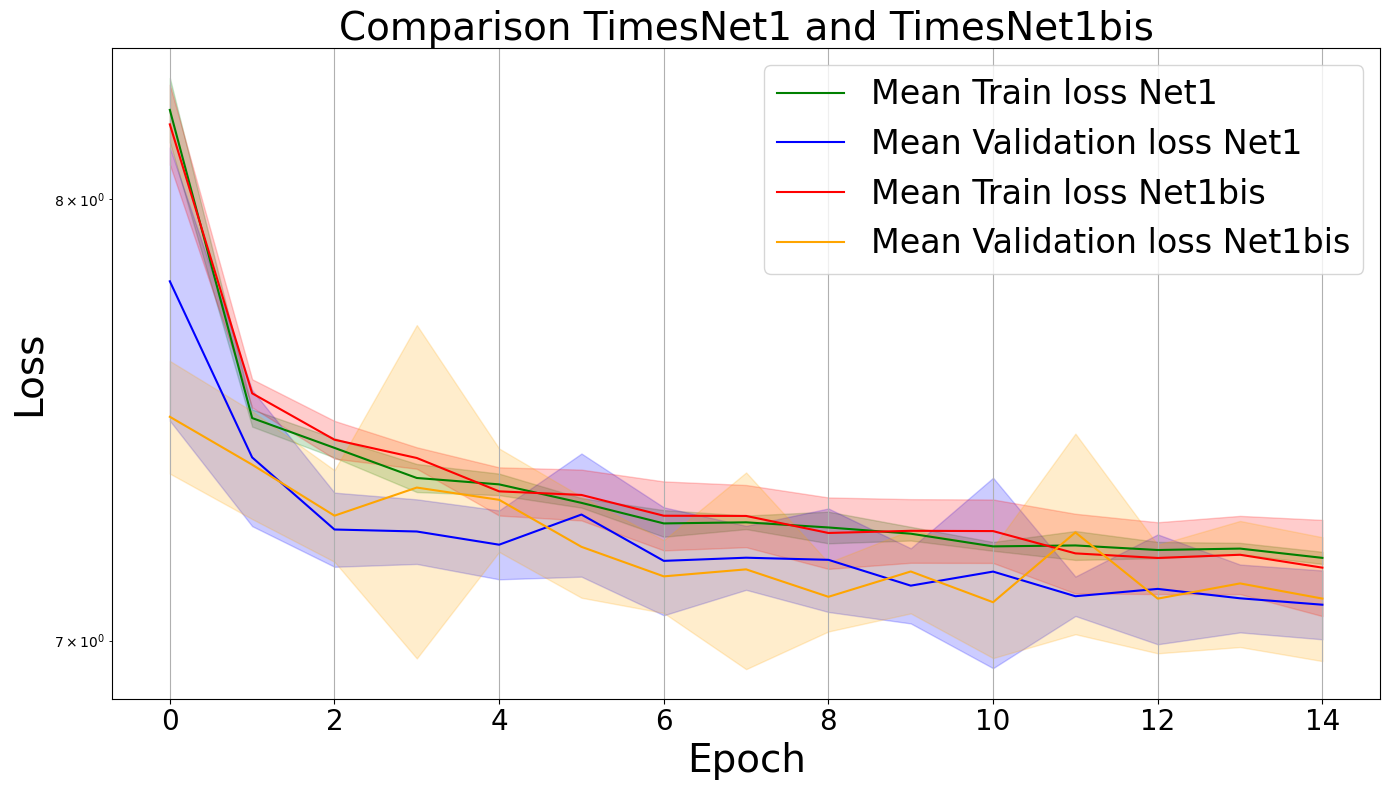

In [ ]:
df_losses = pd.read_csv('model_losses_statistical_comparison.csv')
seeds = [0, 1, 2, 3, 4]

# Get the number of epochs from the DataFrame
num_epochs = df_losses.shape[0]
epochs = range(num_epochs)

# TimesNet1 (Net1)
val_err1_cols = [f'seed_{s}_val_err1' for s in seeds]
train_err1_cols = [f'seed_{s}_train_err1' for s in seeds]


mean_val_err1 = df_losses[val_err1_cols].mean(axis=1)
std_val_err1 = df_losses[val_err1_cols].std(axis=1)

mean_train_err1 = df_losses[train_err1_cols].mean(axis=1)
std_train_err1 = df_losses[train_err1_cols].std(axis=1)

# TimesNet1bis (Net2)
val_err2_cols = [f'seed_{s}_val_err2' for s in seeds]
train_err2_cols = [f'seed_{s}_train_err2' for s in seeds]

mean_val_err2 = df_losses[val_err2_cols].mean(axis=1)
std_val_err2 = df_losses[val_err2_cols].std(axis=1)

mean_train_err2 = df_losses[train_err2_cols].mean(axis=1)
std_train_err2 = df_losses[train_err2_cols].std(axis=1)


plt.figure(figsize=(14, 8))

# TimesNet1 plots
plt.semilogy(epochs, mean_train_err1, color='green', label='Mean Train loss Net1')
plt.fill_between(epochs, mean_train_err1 - std_train_err1, mean_train_err1 + std_train_err1, color='green', alpha=0.2)

plt.semilogy(epochs, mean_val_err1, color='blue', label='Mean Validation loss Net1')
plt.fill_between(epochs, mean_val_err1 - std_val_err1, mean_val_err1 + std_val_err1, color='blue', alpha=0.2)

# TimesNet1bis plots
plt.semilogy(epochs, mean_train_err2, color='red', label='Mean Train loss Net1bis')
plt.fill_between(epochs, mean_train_err2 - std_train_err2, mean_train_err2 + std_train_err2, color='red', alpha=0.2)

plt.semilogy(epochs, mean_val_err2, color='orange', label='Mean Validation loss Net1bis')
plt.fill_between(epochs, mean_val_err2 - std_val_err2, mean_val_err2 + std_val_err2, color='orange', alpha=0.2)

plt.xlabel('Epoch', fontsize=28)
plt.ylabel('Loss', fontsize=28)
plt.title('Comparison TimesNet1 and TimesNet1bis', fontsize=28)
plt.grid(True)
plt.legend(loc='best', fontsize=24)
plt.tick_params(axis='both', labelsize=20)
plt.tight_layout()
plt.show()

# **Net2 Training**

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [ ]:
#Test to see if Net2 is reliable

num_epochs = 30
lr = 1e-4
loss_fn = torch.nn.MSELoss()
seeds = [0, 1, 2, 3, 4]
GRADIENT_CLIP_VALUE = 1.0

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Training device: {device}")

all_val_err1 = []
all_train_err1 = []

for seed in seeds:
    print(f'####################################')
    print(f'TRAINING WITH SEED: {seed}')
    print(f'####################################')
    set_seed(seed)

    timesnet1 = TimesNet2(
    seq_len=sequence_lenght,
    pred_len = prediction_lenght,
    n_channels=1,
    d_model=1,
    top_k=top_k,
    dropoout=0.1,
    activation="relu"
    )

    optim1 = torch.optim.Adam(timesnet1.parameters(), lr=lr, weight_decay=1e-4)

    train_err1 = []
    val_err1 = []

    print('TRAINING Net1')
    for i in range(num_epochs):
        print(f'# EPOCH {i}')
        timesnet1.train()
        losses = []
        # Iterate the dataloader
        for something in train_dataloader:
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = timesnet1(x)
            loss = loss_fn(time_data,y)

            # Backward pass
            optim1.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(timesnet1.parameters(), GRADIENT_CLIP_VALUE) # Gradient Clipping
            optim1.step()

            losses.append(loss.detach().cpu().numpy())

        train_loss = np.mean(losses)
        print(f"AVERAGE TRAIN LOSS: {train_loss}")

        timesnet1.eval()
        losses = []
        with torch.no_grad():
          for something in val_dataloader:
            something = something.to(device)
            x = something[:, :-prediction_lenght, :]
            y = something[:, -prediction_lenght:, :]

            time_data = timesnet1(x)
            loss = loss_fn(time_data,y)

            losses.append(loss.detach().cpu().numpy())

        val_loss = np.mean(losses)
        print(f"AVERAGE VAL LOSS: {val_loss}")

        train_err1.append(train_loss)
        val_err1.append(val_loss)

    torch.save(timesnet1.state_dict(), f'Net2_seed_{i}.pth')


    all_val_err1.append(val_err1)
    all_train_err1.append(train_err1)

all_val_err1 = np.array(all_val_err1)
all_train_err1 = np.array(all_train_err1)

df_all_errors = pd.DataFrame({
    'seed_0_val_err1': all_val_err1[0, :],
    'seed_1_val_err1': all_val_err1[1, :],
    'seed_2_val_err1': all_val_err1[2, :],
    'seed_3_val_err1': all_val_err1[3, :],
    'seed_4_val_err1': all_val_err1[4, :],
    'seed_0_train_err1': all_train_err1[0, :],
    'seed_1_train_err1': all_train_err1[1, :],
    'seed_2_train_err1': all_train_err1[2, :],
    'seed_3_train_err1': all_train_err1[3, :],
    'seed_4_train_err1': all_train_err1[4, :],
})
df_all_errors.to_csv('model_losses_NET2.csv', index=False)

print("Training complete for all seeds")

In [ ]:
#Results
df_loaded_errors = pd.read_csv('model_losses_NET2.csv')

plt.figure(figsize=(14, 8))

for seed_idx in range(len(seeds)):
    plt.semilogy(df_loaded_errors[f'seed_{seed_idx}_train_err1'], label=f'Train loss Net1 (Seed {seed_idx})', color='green', alpha=0.6)
    plt.semilogy(df_loaded_errors[f'seed_{seed_idx}_val_err1'], label=f'Validation loss Net1 (Seed {seed_idx})', color='blue', alpha=0.6)


from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='green', lw=2, label='Average Train loss Net1'),
    Line2D([0], [0], color='blue', lw=2, label='Average Validation loss Net1')
]

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Losses for TimesNet1 and TimesNet1bis Across Different Seeds')
plt.grid(True)
plt.legend(handles=legend_elements, loc='best')
plt.show()

In [ ]:
#The code for finding hyperparameters can be found in the attached files

In [ ]:
#Long Training - single channel
num_epochs = 100
lr = 3.25e-4
loss_fn = torch.nn.MSELoss()

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Training device: {device}")

all_val_err1 = []
all_train_err1 = []

set_seed(0)

timesnet1 = TimesNet2(
    seq_len=sequence_lenght,
    pred_len=prediction_lenght,
    n_channels=1,
    d_model=32,
    top_k=9,
    dropout=0.1,
    activation='relu'
).to(device)

optim1 = torch.optim.Adam(timesnet1.parameters(), lr=lr, weight_decay=1e-4)

train_err1 = []
val_err1 = []

print('TRAINING Net2')
for i in range(num_epochs):
    print(f'# EPOCH {i}')
    te = train_epoch(timesnet1, device, train_dataloader, loss_fn, optim1)
    ve = val_epoch(timesnet1, device, val_dataloader, loss_fn, optim1)
    train_err1.append(te)
    val_err1.append(ve)

torch.save(timesnet1.state_dict(), 'Net2_s.pth')
#Usefull later: timesnet1.load_state_dict(torch.load('file.pth'))


all_val_err1.append(val_err1)
all_train_err1.append(train_err1)

all_val_err1 = np.array(all_val_err1)
all_train_err1 = np.array(all_train_err1)

df_all_errors = pd.DataFrame({
    'val_err': all_val_err1[0, :],
    'train_err': all_train_err1[0, :]
})
df_all_errors.to_csv('Net2_losses_s.csv', index=False)

# **Net3  Training**

In [ ]:
#The code for finding hyperparameters and the long training can be found in the attached files

# **Net4  Training**

In [ ]:
#The code for finding hyperparameters and the long training can be found in the attached files

# **Final results**

## Example of code used to test each network


In [ ]:
#TEST DATASET

def dataset_creation(url_list, seq_len=96, train_percentage = 0.8, slipping = 0):
    """
    ------------------------------------------------------------------------
      Receives the list of urls as input (give them ordered from past to present)
      and gives back a usable datase
    ------------------------------------------------------------------------
    Params
    -----------
    url_list                                                 the list of url
    ------------------------------------------------------------------------
    Return
    ----------
    dataset: ndarray                                         the dataset
    ------------------------------------------------------------------------
    """
    def download_and_clean_data(url):
        #converting data in pandas dataframe
        df = pd.read_csv(url, compression='zip', encoding='ISO-8859-1')

        if 'Date Time' in df.columns:
            df_numeric = df.drop(columns=['Date Time'])

        return df_numeric.to_numpy()

    data = []

    for i, url in enumerate(url_list):
        try:
            data.append(download_and_clean_data(url))
            print(f"Downloaded {i}-th file: {url}")
            print(f"Remaning {len(url_list)-i} files")
        except Exception as e:
            print("Failed to download: ", url)


    data= np.concatenate(data)

    #cut the ones that avoid integer div
    remainder = data.shape[0] % seq_len
    if remainder != 0:
        data = data[:-remainder]

    if slipping > 0:
        division_grid = np.linspace(0,1, num=slipping, endpoint=False)
        for i in division_grid:
            data_to_add = data[int(seq_len*i):]
            remainder = data_to_add.shape[0] % seq_len
            if remainder != 0:
                data_to_add = data_to_add[:-remainder]

            data = np.concatenate([data, data_to_add])

    #reshape (B, T, c)
    data = data.reshape((data.shape[0]//seq_len, seq_len, data.shape[1]))

    #shuffle data
    idx = np.arange(data.shape[0])
    np.random.shuffle(idx)
    data = data[idx, :, :]

    #split train and test dataset
    train_dataset = data[:int(train_percentage*data.shape[0])]
    test_dataset = data[int(train_percentage*data.shape[0]):]


    return train_dataset, test_dataset


x, _ = dataset_creation([
        "https://www.bgc-jena.mpg.de/wetter/mpi_roof.zip"],
                        seq_len=192,
                        train_percentage=1,
                        slipping=0)

In [ ]:
#Single-channel

timesnet = #NAME OF THE NET TO TEST

timesnet.load_state_dict(torch.load('model_weights.pth', map_location='cpu'))


timesnet.eval()
x1 = x[:,:,1:2]

print(x1.shape)

x_tensor = torch.tensor(x1, dtype=torch.float32)
pred = timesnet(x_tensor[:, :96,:])

true = x_tensor[:,96:,]
diff = (true - pred)
test_loss = (true - pred)**2
mean = diff.mean(dim=0).detach().numpy()[:,0]
std = diff.std(dim=0).detach().numpy()[:,0]
test_loss = test_loss.mean().detach().numpy()
print("Test loss", test_loss)

In [ ]:
#Multi-channel
import joblib

timesnet_pca = #NAME OF THE NET TO TEST


timesnet_pca.load_state_dict(torch.load('model_weights.pth', map_location='cpu'))
timesnet_pca.eval()

scaler = joblib.load('scaler_model.joblib')
pca = joblib.load('pca_model.joblib')

n_components = pca.n_components_

print(x.shape)
N, T_tot, C = x.shape

x_flat = x.reshape(-1, C)          # (N*T_tot, C)
x_scaled = scaler.transform(x_flat)
x_pca = pca.transform(x_scaled)     # (N*T_tot, n_components)

x_pca = x_pca.reshape(N, T_tot, n_components)  # (N, T_tot, n_components)
print(x_pca.shape)
x_pca_tensor = torch.tensor(x_pca, dtype=torch.float32)

# --- Predizione ---
pred_pca = timesnet_pca(x_pca_tensor[:, :96, :])   # (N, pred_len, n_components)
true_pca = x_pca_tensor[:, 96:, :]                  # (N, pred_len, n_components)

diff_pca = true_pca - pred_pca

mean_pca = diff_pca.mean(dim=0).detach().numpy()   # (pred_len, n_components)
std_pca = diff_pca.std(dim=0).detach().numpy()     # (pred_len, n_components)

def inverse_pca_scale(x_pca_tensor, pca, scaler):
    """
    x_pca_tensor: (N, T, n_components) tensor
    Ritorna: (N, T, C_original) numpy array
    """
    N, T, n_comp = x_pca_tensor.shape
    x_flat = x_pca_tensor.detach().numpy().reshape(-1, n_comp)
    x_unpca = pca.inverse_transform(x_flat)          # (N*T, C_original)
    x_unscaled = scaler.inverse_transform(x_unpca)    # (N*T, C_original)
    return x_unscaled.reshape(N, T, -1)

pred_orig = inverse_pca_scale(pred_pca, pca, scaler)   # (N, pred_len, C_original)
true_orig = inverse_pca_scale(true_pca, pca, scaler)   # (N, pred_len, C_original)

diff_orig = true_orig - pred_orig
test_loss = (true_orig - pred_orig)**2

test_lossT = test_loss.mean(axis=0).mean(axis=0)[1]
print("Test loss Temperature", test_lossT)

mean_orig = diff_orig.mean(axis=0)   # (pred_len, C_original)
std_orig = diff_orig.std(axis=0)     # (pred_len, C_original)
test_loss = test_loss.mean()
print("Test loss", test_loss)

In [ ]:
with open("Net_data.pkl", "wb") as f:
    pickle.dump((mean_orig[:,0], std_orig[:,0], mean, std), f)

## Results



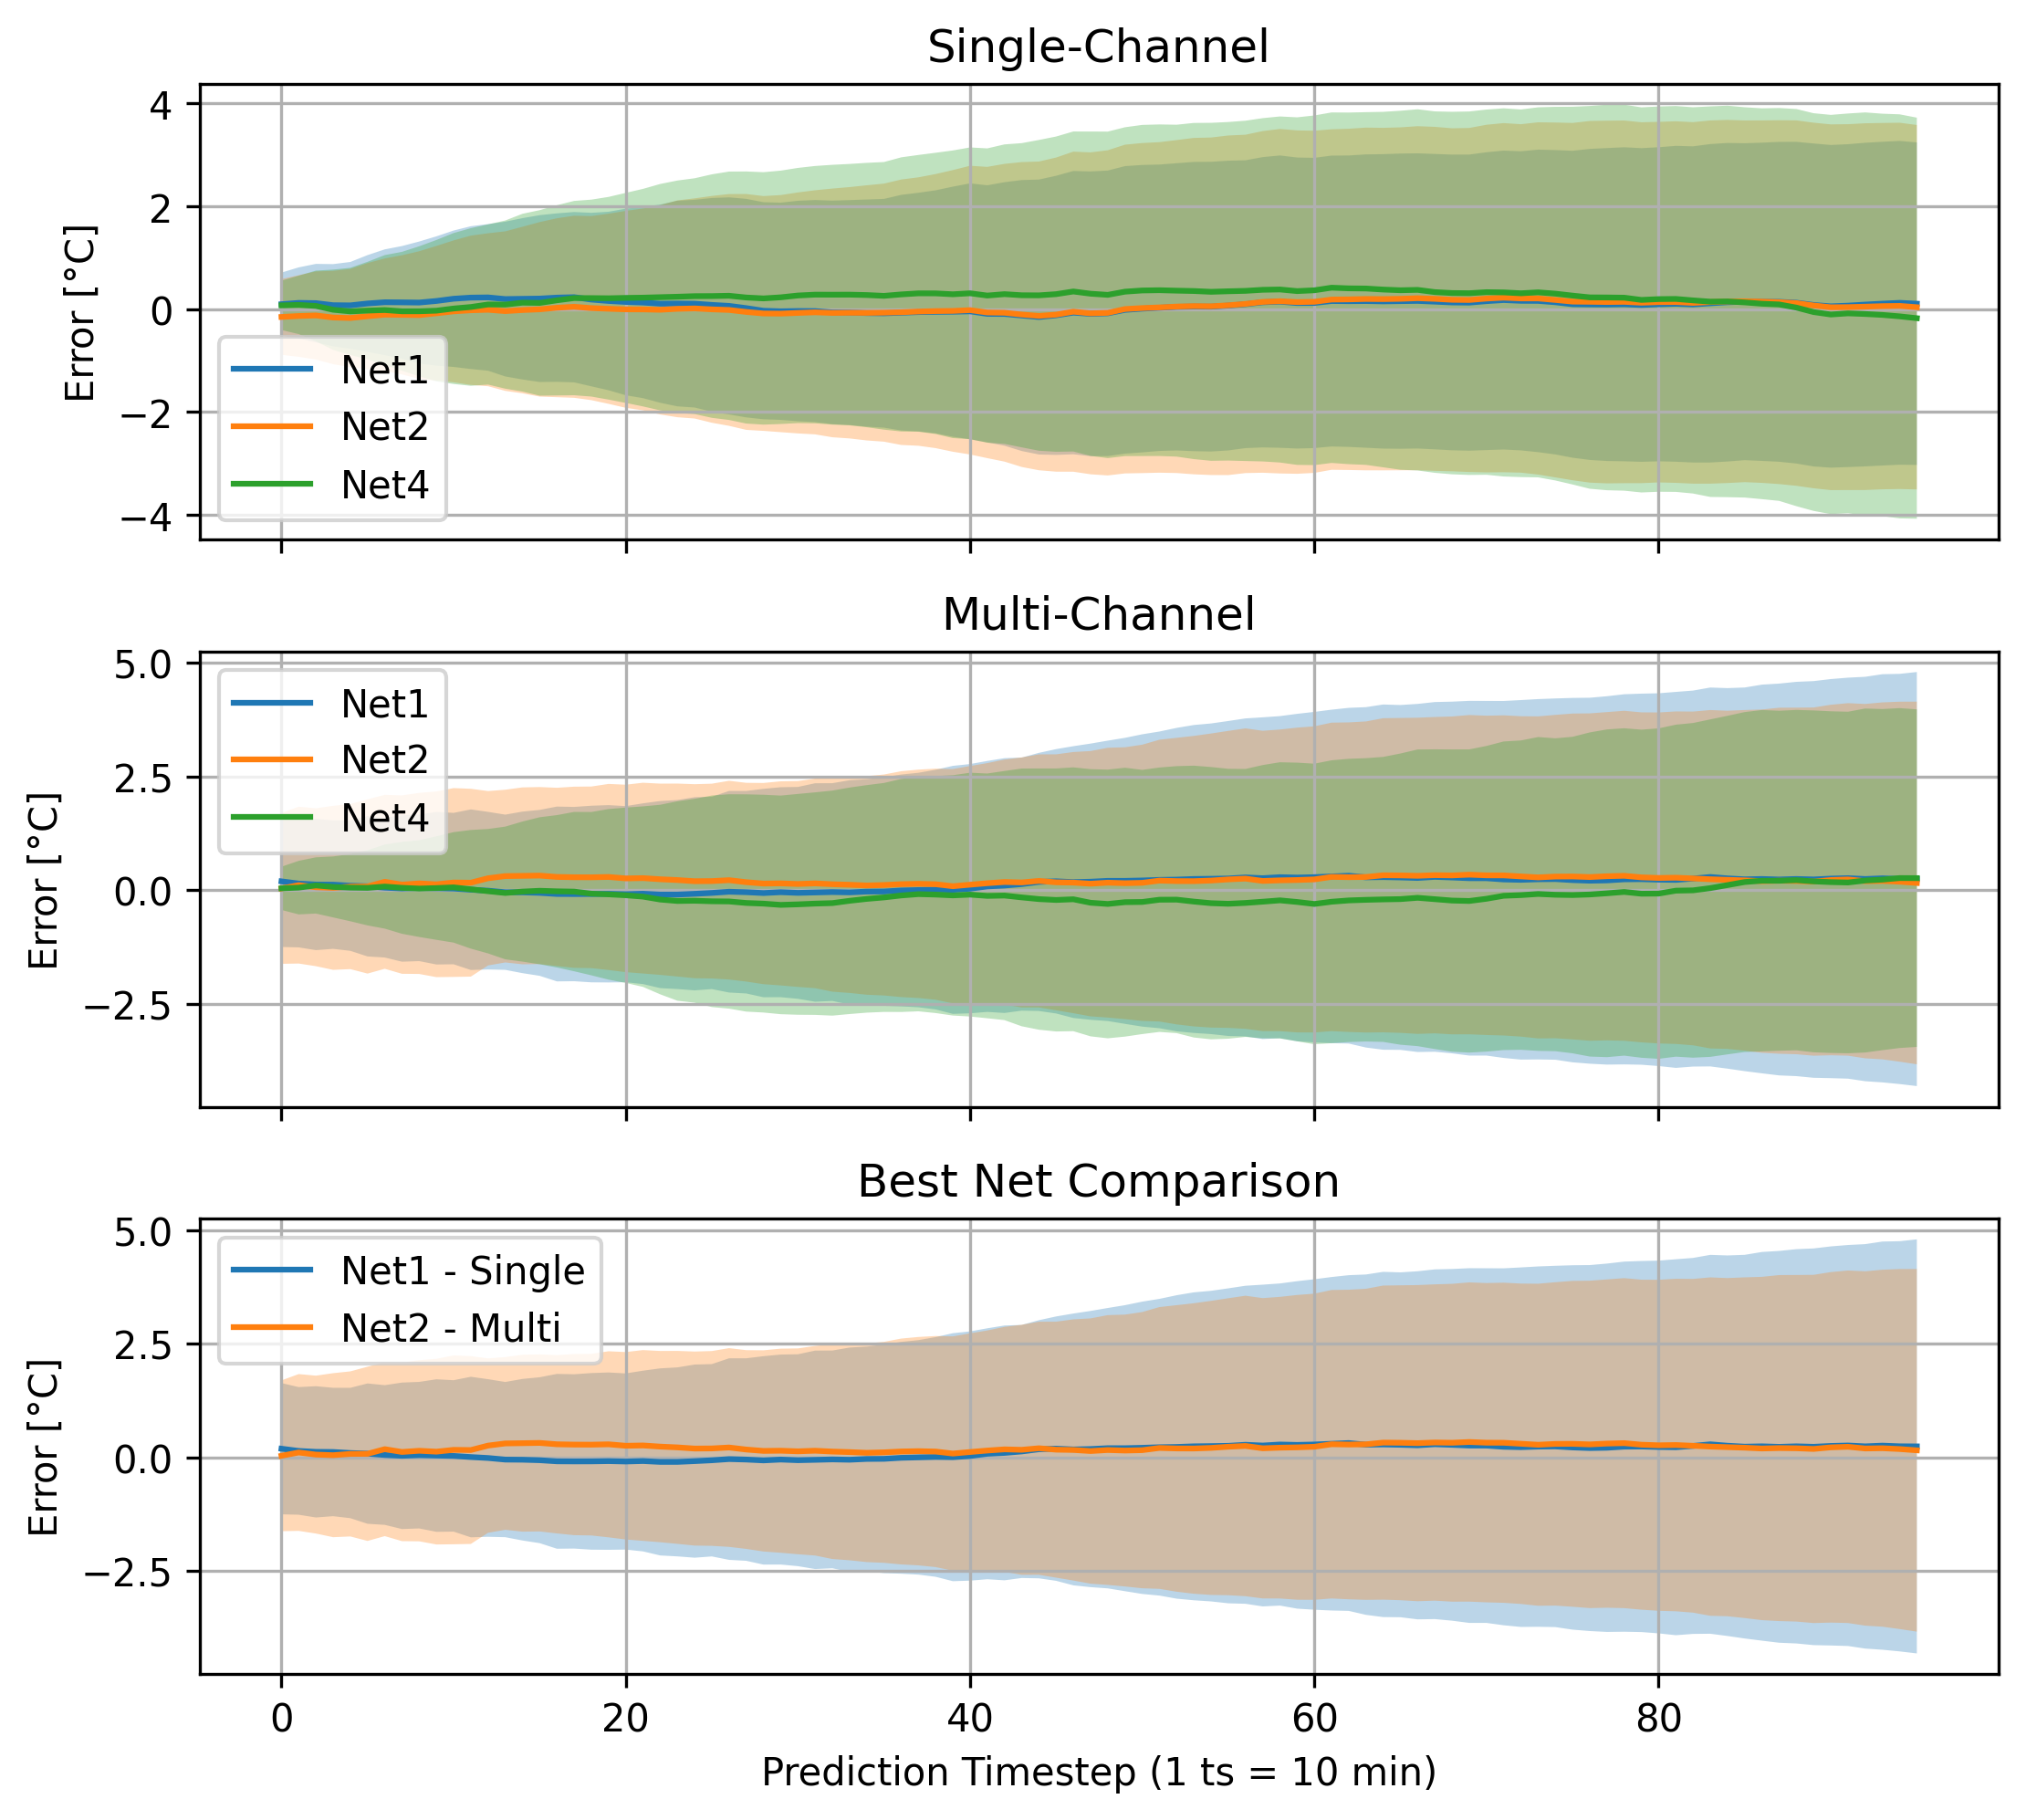

In [ ]:
#Plot of the results
with open("Final_results/fardo_data.pkl", "rb") as f:
  d = pickle.load(f)

with open("Final_results/saccon_data.pkl", "rb") as f:
  d1 = pickle.load(f)

with open("Final_results/pesce_data_uni.pkl", "rb") as f:
  d2 = pickle.load(f)

with open("Final_results/pesce_data_multi.pkl", "rb") as f:
  d3 = pickle.load(f)



mean_pca_nob, std_pca_nob, mean, std = d
mean_pca_nob1, std_pca_nob1, mean1, std1 = d1
aa, bb, mean_pca_nob2, std_pca_nob2 = d3
mean2, std2 = d2

fig, axs = plt.subplots(3, 1, figsize=(7.5, 6.75), dpi=300, sharex=True)


# Single-channel

axs[0].plot(mean, label="Net1")
axs[0].fill_between(range(len(std)), mean+std, mean-std, alpha=0.3)

axs[0].plot(mean1, label="Net2")
axs[0].fill_between(range(len(std1)), mean1+std1, mean1-std1, alpha=0.3)

axs[0].plot(mean2, label="Net4")
axs[0].fill_between(range(len(std2)), mean2+std2, mean2-std2, alpha=0.3)

axs[0].set_title("Single-Channel")
axs[0].set_ylabel("Error [°C]")
axs[0].grid(True)
axs[0].legend()


# Multi-channel

axs[1].plot(mean_pca_nob, label="Net1")
axs[1].fill_between(range(len(std_pca_nob)), mean_pca_nob+std_pca_nob, mean_pca_nob-std_pca_nob, alpha=0.3)

axs[1].plot(mean_pca_nob1, label="Net2")
axs[1].fill_between(range(len(std_pca_nob1)), mean_pca_nob1+std_pca_nob1, mean_pca_nob1-std_pca_nob1, alpha=0.3)

axs[1].plot(mean_pca_nob2, label="Net4")
axs[1].fill_between(range(len(std_pca_nob2)), mean_pca_nob2+std_pca_nob2, mean_pca_nob2-std_pca_nob2, alpha=0.3)

axs[1].set_title("Multi-Channel")
axs[1].set_ylabel("Error [°C]")
axs[1].grid(True)
axs[1].legend()

# BEST COMPARISON
axs[2].plot(mean_pca_nob, label="Net1 - Single")
axs[2].fill_between(range(len(std_pca_nob)), mean_pca_nob+std_pca_nob, mean_pca_nob-std_pca_nob, alpha=0.3)

axs[2].plot(mean_pca_nob1, label="Net2 - Multi")
axs[2].fill_between(range(len(std_pca_nob1)), mean_pca_nob1+std_pca_nob1, mean_pca_nob1-std_pca_nob1, alpha=0.3)

axs[2].set_title("Best Net Comparison")
axs[2].set_xlabel("Prediction Timestep (1 ts = 10 min)")
axs[2].set_ylabel("Error [°C]")
axs[2].grid(True)
axs[2].legend()

plt.tight_layout()

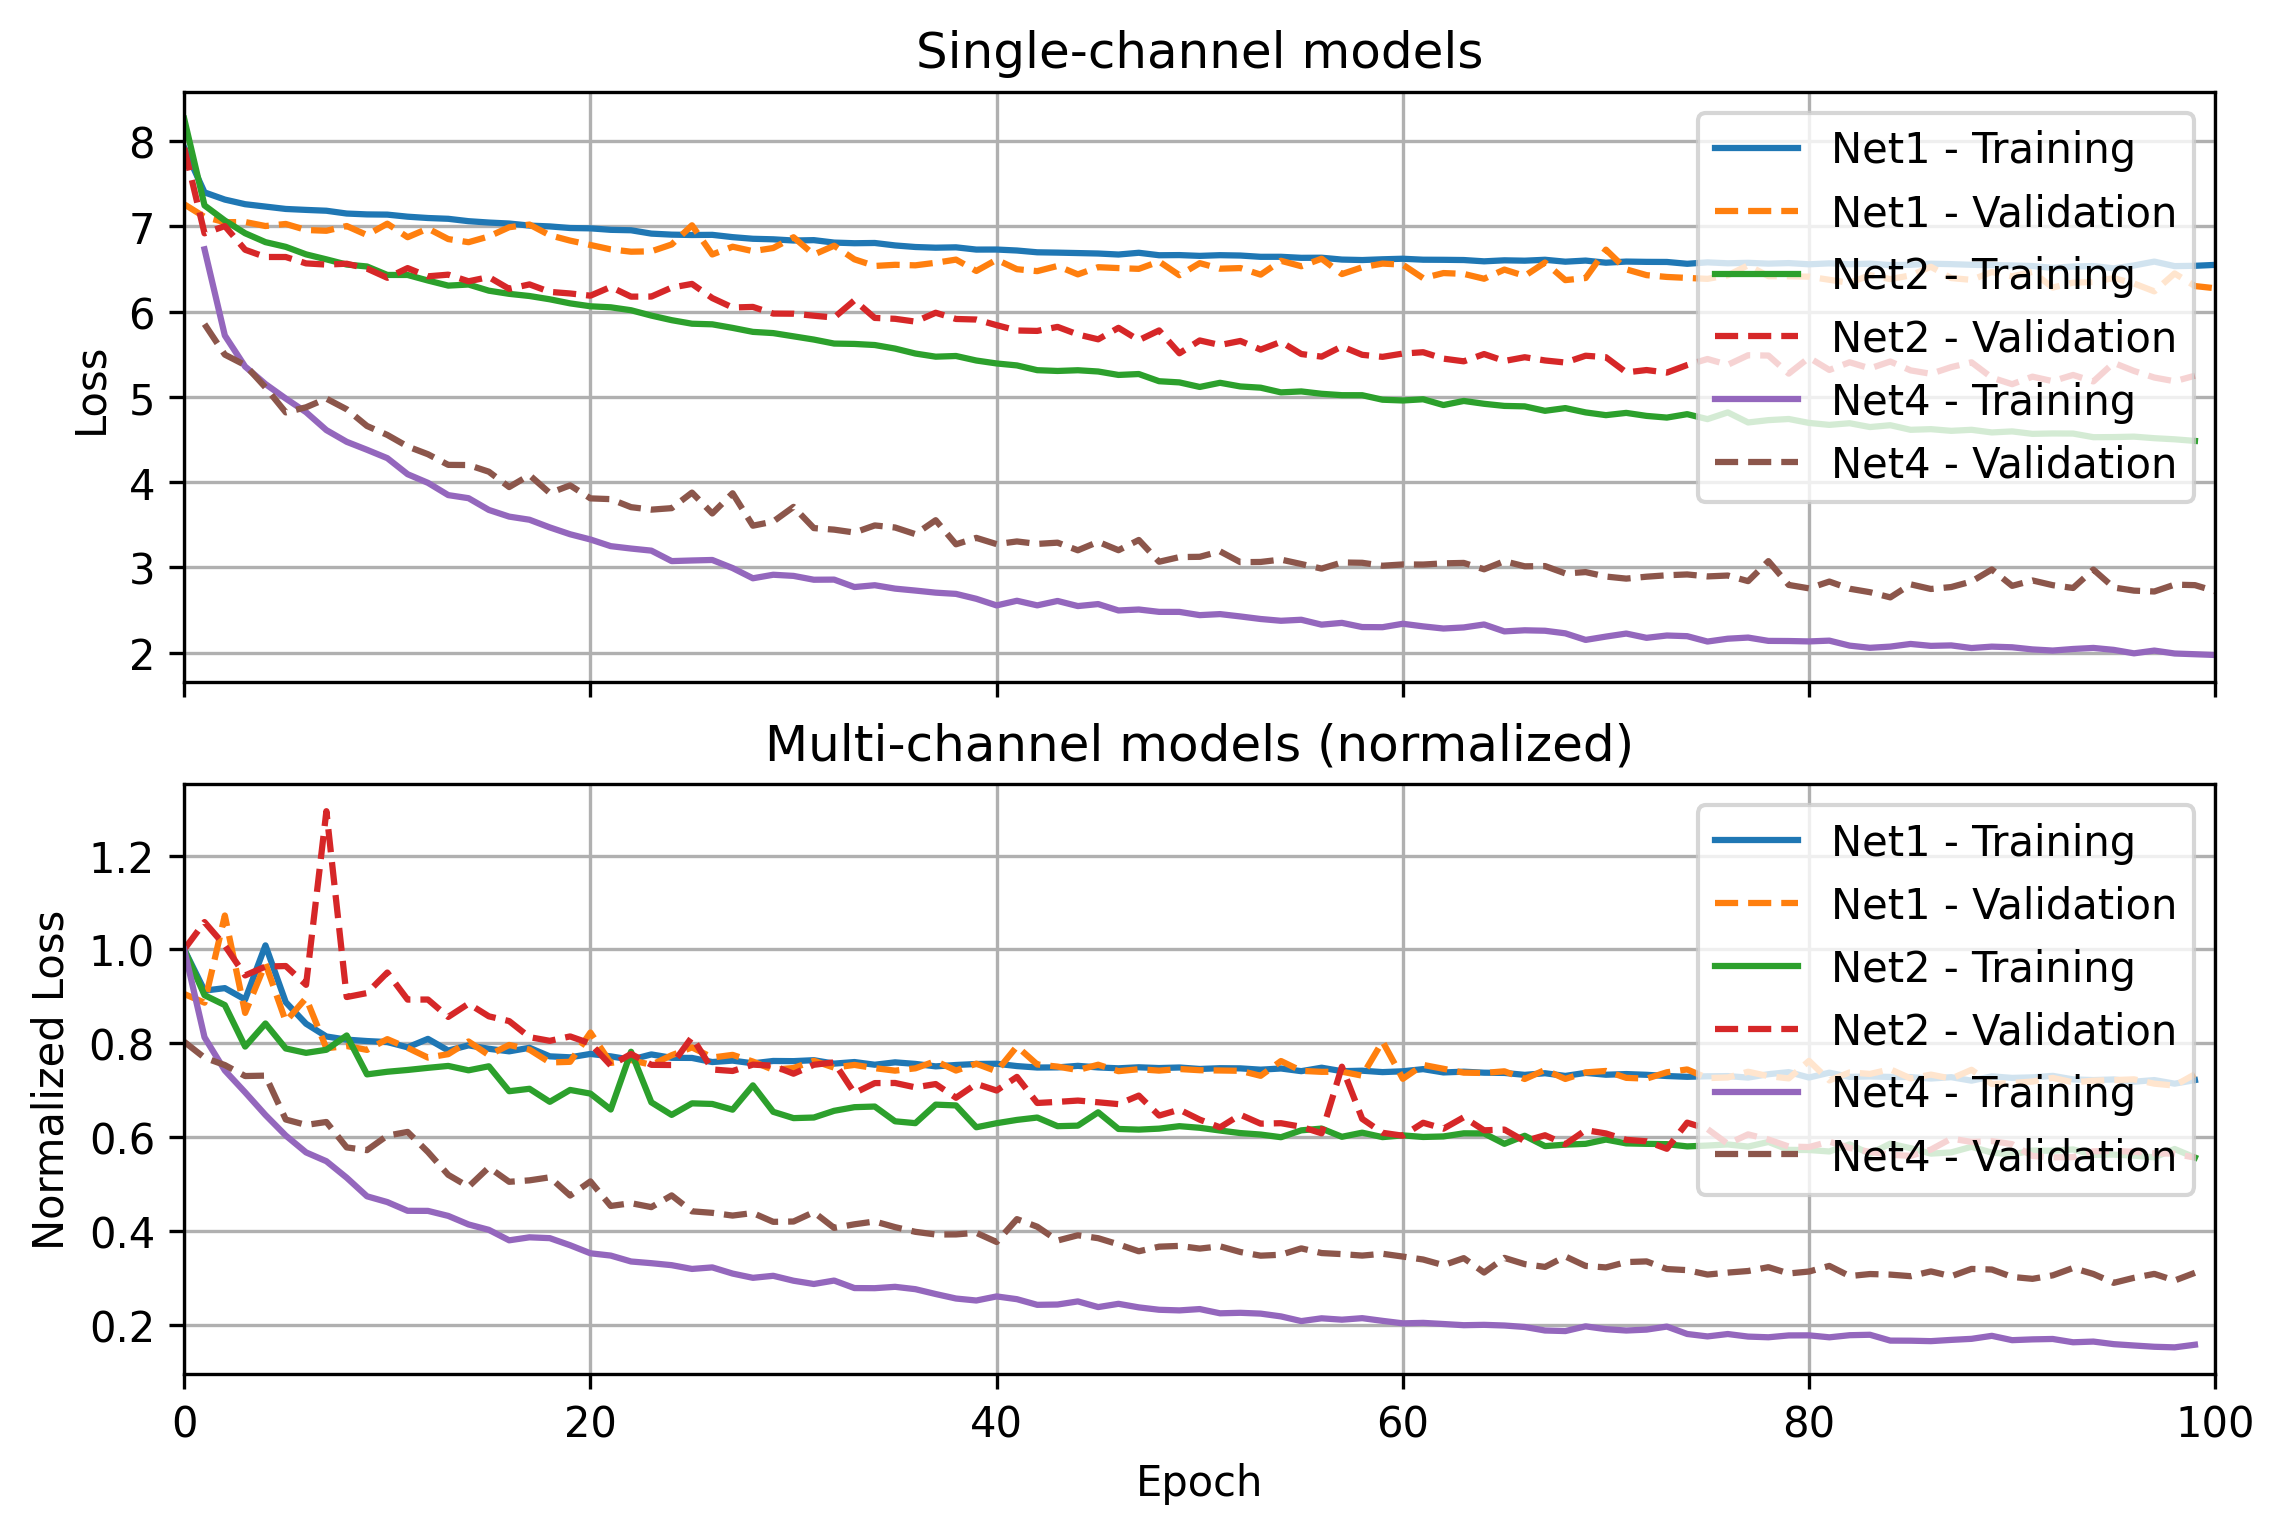

In [ ]:
fig, axs = plt.subplots(
    2, 1,
    figsize=(7.5, 5),
    dpi=300,
    sharex=True,
    constrained_layout=True

)

# Single-channel models
net1 = pd.read_csv("Final_results/net1_loss_s.csv")
net2 = pd.read_csv("Final_results/net2_loss_s.csv")
net4 = pd.read_csv("Final_results/net4_loss_s.csv")

ax = axs[0]
ax.plot(net1["Training_Loss"], label="Net1 - Training")
ax.plot(net1["Validation_Loss"], "--", label="Net1 - Validation")
ax.plot(net2["seed_0_train_err1"], label="Net2 - Training")
ax.plot(net2["seed_0_val_err1"], "--", label="Net2 - Validation")
ax.plot(net4["epoch"], net4["train_loss"], label="Net4 - Training")
ax.plot(net4["epoch"], net4["val_loss"], "--", label="Net4 - Validation")
ax.set_xlim(0, 100)
ax.set_ylabel("Loss")
ax.set_title("Single-channel models")
ax.grid(True)
ax.legend(loc="upper right")

# Multi-channel models (normalized)

net1 = pd.read_csv("Final_results/net1_loss_m.csv")
net2 = pd.read_csv("Final_results/net2_loss_m.csv")
net3 = pd.read_csv("Final_results/net4_loss_m.csv")

norm1 = net1["train_loss"].iloc[0]
norm2 = net2["train_loss"].iloc[0]
norm3 = net3["train_loss"].iloc[0]

ax = axs[1]
ax.plot(net1["train_loss"] / norm1, label="Net1 - Training")
ax.plot(net1["val_loss"] / norm1, "--", label="Net1 - Validation")
ax.plot(net2["train_loss"] / norm2, label="Net2 - Training")
ax.plot(net2["val_loss"] / net2["val_loss"].iloc[0], "--", label="Net2 - Validation")
ax.plot(net3["train_loss"] / norm3, label="Net4 - Training")
ax.plot(net3["val_loss"] / norm3, "--", label="Net4 - Validation")
ax.set_xlim(0, 100)
ax.set_xlabel("Epoch")
ax.set_ylabel("Normalized Loss")
ax.set_title("Multi-channel models (normalized)")
ax.grid(True)
ax.legend(loc="upper right")
plt.show()